# Predicción de Cancelaciones de Reservas Hoteleras
## Proyecto de Machine Learning

### Máster en Data Science & Inteligencia Artificial

**Objetivo del proyecto**

Desarrollar un modelo de Machine Learning capaz de estimar, en el momento de realizar una reserva, la probabilidad de que esta sea cancelada.

El modelo pretende servir como herramienta de apoyo al equipo de Revenue Management, permitiendo identificar reservas de alto riesgo y aplicar acciones preventivas de forma selectiva.

### Problema de Machine Learning

Se trata de un problema de **clasificación binaria supervisada**, donde la variable objetivo es:

- `is_canceled = 0`: reserva no cancelada.
- `is_canceled = 1`: reserva cancelada.

Además del rendimiento predictivo, el proyecto tendrá en cuenta la interpretabilidad del modelo y el impacto de negocio asociado a los distintos tipos de error.

In [1]:
# Comprobación del entorno de trabajo

import sys

print("Versión de Python:", sys.version)
print("Entorno utilizado:", sys.executable)
print("¡Entorno de trabajo configurado correctamente!")

Versión de Python: 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
Entorno utilizado: c:\Users\HP\Desktop\ml-cancelaciones-hoteleras\.venv\Scripts\python.exe
¡Entorno de trabajo configurado correctamente!


In [2]:
# Instalación de librerías necesarias para el análisis inicial

%pip install pandas openpyxl numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ============================================================
# 1. CARGA DEL DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ruta del dataset
DATA_PATH = "../data/reservas_hoteleras.xlsx"

# Carga de los datos
df = pd.read_excel(DATA_PATH)

print("Dataset cargado correctamente.")
print(f"Número de reservas: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")

Dataset cargado correctamente.
Número de reservas: 119,390
Número de variables: 32


In [4]:
# ============================================================
# 2. INSPECCIÓN INICIAL DEL DATASET
# ============================================================

print("Primeras 5 reservas del dataset:")
display(df.head())

print("\nDimensiones del dataset:")
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")

print("\nListado de variables:")
for i, columna in enumerate(df.columns, start=1):
    print(f"{i:02d}. {columna}")

Primeras 5 reservas del dataset:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Dimensiones del dataset:
119,390 filas x 32 columnas

Listado de variables:
01. hotel
02. is_canceled
03. lead_time
04. arrival_date_year
05. arrival_date_month
06. arrival_date_week_number
07. arrival_date_day_of_month
08. stays_in_weekend_nights
09. stays_in_week_nights
10. adults
11. children
12. babies
13. meal
14. country
15. market_segment
16. distribution_channel
17. is_repeated_guest
18. previous_cancellations
19. previous_bookings_not_canceled
20. reserved_room_type
21. assigned_room_type
22. booking_changes
23. deposit_type
24. agent
25. company
26. days_in_waiting_list
27. customer_type
28. adr
29. required_car_parking_spaces
30. total_of_special_requests
31. reservation_status
32. reservation_status_date


In [5]:
# ============================================================
# 3. CALIDAD Y ESTRUCTURA DE LOS DATOS
# ============================================================

resumen = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Nulos": df.isnull().sum(),
    "% Nulos": (df.isnull().mean() * 100).round(2),
    "Valores únicos": df.nunique()
})

display(resumen)

,Tipo,Nulos,% Nulos,Valores únicos
hotel,str,0,0.00,2
is_canceled,int64,0,0.00,2
lead_time,int64,0,0.00,479
arrival_date_year,int64,0,0.00,3
arrival_date_month,str,0,0.00,12
arrival_date_week_number,int64,0,0.00,53
arrival_date_day_of_month,int64,0,0.00,31
stays_in_weekend_nights,int64,0,0.00,17
stays_in_week_nights,int64,0,0.00,35
adults,int64,0,0.00,14


In [6]:
# ============================================================
# 4. ANÁLISIS DE VALORES NULOS
# ============================================================

nulos = resumen[resumen["Nulos"] > 0].sort_values(
    by="% Nulos",
    ascending=False
)

print(f"Variables con valores nulos: {len(nulos)}")
display(nulos)

Variables con valores nulos: 4


,Tipo,Nulos,% Nulos,Valores únicos
company,float64,112593,94.31,352
agent,float64,16340,13.69,333
country,str,488,0.41,177
children,float64,4,0.00,5


In [7]:
# ============================================================
# 5. REVISIÓN DE POSIBLE DATA LEAKAGE
# ============================================================

columnas_revision = [
    "is_canceled",
    "reservation_status",
    "reservation_status_date"
]

for columna in columnas_revision:
    print(f"\n--- {columna} ---")
    print(df[columna].value_counts(dropna=False).head(15))


--- is_canceled ---
is_canceled
0    75166
1    44224
Name: count, dtype: int64

--- reservation_status ---
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

--- reservation_status_date ---
reservation_status_date
2015-10-21    1461
2015-07-06     805
2016-11-25     790
2015-01-01     763
2016-01-18     625
2015-07-02     469
2016-12-07     450
2015-12-18     423
2016-02-09     412
2016-04-04     382
2017-01-24     343
2016-11-21     340
2016-03-15     329
2017-01-19     321
2017-02-02     315
Name: count, dtype: int64


### Prevención de Data Leakage

El objetivo del modelo es predecir el riesgo de cancelación utilizando únicamente información disponible en el momento de realizar la reserva. Por este motivo, es necesario excluir cualquier variable que contenga información generada posteriormente o que revele directamente el resultado final de la reserva.

Se identifican dos variables con riesgo evidente de **data leakage**:

- **`reservation_status`**: indica el estado final de la reserva (`Check-Out`, `Canceled` o `No-Show`). Por tanto, revela directamente el resultado que se pretende predecir.
- **`reservation_status_date`**: indica la fecha asociada al estado final de la reserva y contiene información posterior al momento en el que se desea realizar la predicción.

Incluir estas variables produciría métricas artificialmente elevadas y un modelo que no podría utilizarse de forma realista en producción.

**Decisión:** ambas variables serán excluidas de las variables predictoras antes del entrenamiento.

In [8]:
# ============================================================
# 6. COMPROBACIÓN DE INCONSISTENCIAS
# ============================================================

# Registros duplicados
duplicados = df.duplicated().sum()

# Reservas sin ningún huésped
sin_huespedes = (
    (df["adults"] == 0) &
    (df["children"].fillna(0) == 0) &
    (df["babies"] == 0)
).sum()

# Convertir ADR a numérico para realizar comprobaciones
df["adr"] = pd.to_numeric(df["adr"], errors="coerce")

# ADR negativo
adr_negativo = (df["adr"] < 0).sum()

# Estancias de 0 noches
cero_noches = (
    (df["stays_in_weekend_nights"] == 0) &
    (df["stays_in_week_nights"] == 0)
).sum()

print("CONTROL DE CALIDAD")
print("-" * 40)
print(f"Registros duplicados: {duplicados:,}")
print(f"Reservas sin huéspedes: {sin_huespedes:,}")
print(f"Reservas con ADR negativo: {adr_negativo:,}")
print(f"Reservas con 0 noches: {cero_noches:,}")

CONTROL DE CALIDAD
----------------------------------------
Registros duplicados: 31,994
Reservas sin huéspedes: 180
Reservas con ADR negativo: 1
Reservas con 0 noches: 715


In [9]:
# Comprobación de la variable ADR

print("Tipo de dato de ADR:", df["adr"].dtype)

print("\nEjemplos de valores de ADR:")
print(df["adr"].head(10))

print("\nTipos de valores almacenados en ADR:")
print(df["adr"].apply(type).value_counts())

Tipo de dato de ADR: float64

Ejemplos de valores de ADR:
0      0.0
1      0.0
2     75.0
3     75.0
4     98.0
5     98.0
6    107.0
7    103.0
8     82.0
9    105.5
Name: adr, dtype: float64

Tipos de valores almacenados en ADR:
adr
<class 'float'>    119390
Name: count, dtype: int64


In [10]:
# ============================================================
# 7. INVESTIGACIÓN DE VALORES ANÓMALOS EN ADR
# ============================================================

from datetime import datetime

adr_fechas = df[df["adr"].apply(lambda x: isinstance(x, datetime))]

print(f"Registros de ADR interpretados como fecha: {len(adr_fechas):,}")

display(
    adr_fechas[
        [
            "hotel",
            "arrival_date_year",
            "arrival_date_month",
            "lead_time",
            "adr",
            "is_canceled"
        ]
    ].head(20)
)

Registros de ADR interpretados como fecha: 0


,hotel,arrival_date_year,arrival_date_month,lead_time,adr,is_canceled


In [11]:
# ============================================================
# 8. ANÁLISIS DEL PATRÓN DE FECHAS EN ADR
# ============================================================

from datetime import datetime

adr_fechas = df[df["adr"].apply(lambda x: isinstance(x, datetime))].copy()

print("Fechas diferentes encontradas en ADR:")
print(adr_fechas["adr"].value_counts().sort_index())

print("\nNúmero de fechas diferentes:")
print(adr_fechas["adr"].nunique())

Fechas diferentes encontradas en ADR:
Series([], Name: count, dtype: int64)

Número de fechas diferentes:
0


In [12]:
# ============================================================
# 9. INSPECCIÓN DE CELDAS ORIGINALES DE ADR EN EXCEL
# ============================================================

from openpyxl import load_workbook

archivo = "../data/reservas_hoteleras.xlsx"

wb = load_workbook(archivo, data_only=False)
ws = wb.active

# Localizamos la columna ADR
cabeceras = [celda.value for celda in ws[1]]
col_adr = cabeceras.index("adr") + 1

print("Columna ADR en Excel:", col_adr)
print("\nPrimeros registros problemáticos:\n")

for indice in adr_fechas.index[:15]:
    # +2 porque DataFrame empieza en 0 y Excel tiene cabecera en fila 1
    fila_excel = indice + 2
    celda = ws.cell(row=fila_excel, column=col_adr)

    print(
        f"Fila {fila_excel} | "
        f"valor={repr(celda.value)} | "
        f"tipo={celda.data_type} | "
        f"formato={celda.number_format}"
    )

Columna ADR en Excel: 28

Primeros registros problemáticos:



In [13]:
# ============================================================
# 10. CORRECCIÓN DE LA VARIABLE ADR
# ============================================================

# Convertimos ADR a formato numérico.
# Los valores almacenados erróneamente como fechas pasarán a NaN.
df["adr"] = pd.to_numeric(df["adr"], errors="coerce")

print("Tipo de ADR después de la conversión:", df["adr"].dtype)
print(f"Valores nulos en ADR: {df['adr'].isna().sum():,}")
print(f"Porcentaje de nulos en ADR: {df['adr'].isna().mean() * 100:.3f}%")

print("\nResumen de ADR válido:")
display(df["adr"].describe())

Tipo de ADR después de la conversión: float64
Valores nulos en ADR: 230
Porcentaje de nulos en ADR: 0.193%

Resumen de ADR válido:


count    119160.000000
mean        101.978777
std          50.471840
min          -6.380000
25%          69.670000
50%          95.000000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

In [14]:
# ============================================================
# 11. ANÁLISIS DE VALORES EXTREMOS DE ADR
# ============================================================

print("ADR negativos:")
display(
    df.loc[df["adr"] < 0, [
        "hotel",
        "arrival_date_year",
        "arrival_date_month",
        "adults",
        "children",
        "stays_in_weekend_nights",
        "stays_in_week_nights",
        "adr",
        "is_canceled"
    ]]
)

print("\nNúmero de ADR negativos:", (df["adr"] < 0).sum())

print("\n" + "=" * 60)

print("\nReservas con ADR superior a 1000 €:")
display(
    df.loc[df["adr"] > 1000, [
        "hotel",
        "arrival_date_year",
        "arrival_date_month",
        "adults",
        "children",
        "stays_in_weekend_nights",
        "stays_in_week_nights",
        "adr",
        "is_canceled"
    ]].sort_values("adr", ascending=False)
)

print("\nNúmero de ADR > 1000 €:", (df["adr"] > 1000).sum())

ADR negativos:


,hotel,arrival_date_year,arrival_date_month,adults,children,stays_in_weekend_nights,stays_in_week_nights,adr,is_canceled
14969,Resort Hotel,2017,March,2,0.0,4,6,-6.38,0



Número de ADR negativos: 1


Reservas con ADR superior a 1000 €:


,hotel,arrival_date_year,arrival_date_month,adults,children,stays_in_weekend_nights,stays_in_week_nights,adr,is_canceled
48515,City Hotel,2016,March,2,0.0,0,1,5400.0,1



Número de ADR > 1000 €: 1


In [15]:
# ============================================================
# 12. CUANTIFICACIÓN DE VALORES EXTREMOS DE ADR
# ============================================================

print(f"ADR negativos: {(df['adr'] < 0).sum():,}")
print(f"ADR = 0: {(df['adr'] == 0).sum():,}")
print(f"ADR > 500 €: {(df['adr'] > 500).sum():,}")
print(f"ADR > 1000 €: {(df['adr'] > 1000).sum():,}")

print("\n10 valores ADR más altos:")
print(df["adr"].nlargest(10).to_string(index=False))

ADR negativos: 1
ADR = 0: 1,959
ADR > 500 €: 3
ADR > 1000 €: 1

10 valores ADR más altos:
5400.00
 510.00
 508.00
 451.50
 450.00
 437.00
 426.25
 402.00
 397.38
 392.00


In [16]:
# ============================================================
# 13. INSPECCIÓN DE CASOS EXTREMOS DE ADR
# ============================================================

columnas_inspeccion = [
    "hotel",
    "is_canceled",
    "lead_time",
    "arrival_date_year",
    "arrival_date_month",
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "customer_type",
    "adr"
]

casos_extremos = df.loc[
    (df["adr"] < 0) | (df["adr"] > 1000),
    columnas_inspeccion
]

display(casos_extremos.T)

,14969,48515
hotel,Resort Hotel,City Hotel
is_canceled,0,1
lead_time,195,35
arrival_date_year,2017,2016
arrival_date_month,March,March
adults,2,2
children,0.0,0.0
babies,0,0
stays_in_weekend_nights,4,0
stays_in_week_nights,6,1


In [17]:
# ============================================================
# 14. TRATAMIENTO DE VALORES ANÓMALOS EN ADR
# ============================================================

# Se consideran inválidos:
# - ADR negativos, por carecer de sentido como tarifa diaria.
# - El valor extremo de 5.400 €, claramente aislado respecto
#   al resto de la distribución observada.

mask_adr_anomalo = (df["adr"] < 0) | (df["adr"] > 1000)

print(f"Valores ADR anómalos detectados: {mask_adr_anomalo.sum():,}")

# Los marcamos como NaN en lugar de eliminar las reservas completas
df.loc[mask_adr_anomalo, "adr"] = np.nan

print(f"Nulos totales en ADR tras el tratamiento: {df['adr'].isna().sum():,}")
print(f"Porcentaje de nulos en ADR: {df['adr'].isna().mean() * 100:.3f}%")

print("\nRango válido de ADR tras el tratamiento:")
print(f"Mínimo: {df['adr'].min():.2f} €")
print(f"Máximo: {df['adr'].max():.2f} €")

Valores ADR anómalos detectados: 2
Nulos totales en ADR tras el tratamiento: 232
Porcentaje de nulos en ADR: 0.194%

Rango válido de ADR tras el tratamiento:
Mínimo: 0.00 €
Máximo: 510.00 €


In [18]:
# ============================================================
# 15. ANÁLISIS DE VARIABLES CON VALORES NULOS
# ============================================================

columnas_nulos = ["company", "agent", "country", "children", "adr"]

print("ANÁLISIS DE VALORES NULOS")
print("=" * 55)

for columna in columnas_nulos:
    nulos = df[columna].isna().sum()
    porcentaje = df[columna].isna().mean() * 100

    print(f"\n{columna.upper()}")
    print(f"  Nulos: {nulos:,}")
    print(f"  Porcentaje: {porcentaje:.3f}%")
    print(f"  Valores únicos no nulos: {df[columna].nunique()}")

print("\n" + "=" * 55)

# Comprobamos algunos valores reales de las variables
for columna in ["company", "agent", "country", "children"]:
    print(f"\nEjemplos de {columna}:")
    print(df[columna].dropna().value_counts().head(10))

ANÁLISIS DE VALORES NULOS

COMPANY
  Nulos: 112,593
  Porcentaje: 94.307%
  Valores únicos no nulos: 352

AGENT
  Nulos: 16,340
  Porcentaje: 13.686%
  Valores únicos no nulos: 333

COUNTRY
  Nulos: 488
  Porcentaje: 0.409%
  Valores únicos no nulos: 177

CHILDREN
  Nulos: 4
  Porcentaje: 0.003%
  Valores únicos no nulos: 5

ADR
  Nulos: 232
  Porcentaje: 0.194%
  Valores únicos no nulos: 8821


Ejemplos de company:
company
40.0     927
223.0    784
67.0     267
45.0     250
153.0    215
174.0    149
219.0    141
281.0    138
154.0    133
405.0    119
Name: count, dtype: int64

Ejemplos de agent:
agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
6.0       3290
250.0     2870
241.0     1721
28.0      1666
8.0       1514
Name: count, dtype: int64

Ejemplos de country:
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

Ejemplos de children:
child

In [19]:
# ============================================================
# 16. COMPROBACIÓN DE DUPLICADOS Y RESERVAS SIN HUÉSPEDES
# ============================================================

# Registros duplicados
duplicados = df.duplicated().sum()

# Reservas sin huéspedes
sin_huespedes = (
    (df["adults"] == 0) &
    (df["children"].fillna(0) == 0) &
    (df["babies"] == 0)
).sum()

print("CONTROL DE CALIDAD")
print("=" * 50)
print(f"Registros totales: {len(df):,}")
print(f"Registros duplicados exactos: {duplicados:,}")
print(f"Porcentaje duplicados: {duplicados / len(df) * 100:.2f}%")
print(f"Reservas sin ningún huésped: {sin_huespedes:,}")
print(f"Porcentaje sin huéspedes: {sin_huespedes / len(df) * 100:.3f}%")

CONTROL DE CALIDAD
Registros totales: 119,390
Registros duplicados exactos: 31,998
Porcentaje duplicados: 26.80%
Reservas sin ningún huésped: 180
Porcentaje sin huéspedes: 0.151%


In [20]:
# ============================================================
# 17. ANÁLISIS DE LOS REGISTROS APARENTEMENTE DUPLICADOS
# ============================================================

# Número de filas que pertenecen a grupos duplicados,
# incluyendo la primera aparición
mask_duplicados = df.duplicated(keep=False)
filas_en_grupos_duplicados = mask_duplicados.sum()

# Número de duplicados adicionales
duplicados_adicionales = df.duplicated().sum()

print("ANÁLISIS DE DUPLICADOS")
print("=" * 55)
print(f"Registros totales: {len(df):,}")
print(f"Filas pertenecientes a grupos duplicados: {filas_en_grupos_duplicados:,}")
print(f"Duplicados adicionales detectados: {duplicados_adicionales:,}")

# Frecuencia de las combinaciones repetidas
grupos_duplicados = (
    df[mask_duplicados]
    .value_counts(dropna=False)
    .reset_index(name="repeticiones")
    .sort_values("repeticiones", ascending=False)
)

print(f"\nNúmero de combinaciones distintas repetidas: {len(grupos_duplicados):,}")
print(f"Máximo número de repeticiones de una misma combinación: "
      f"{grupos_duplicados['repeticiones'].max():,}")

print("\nDistribución del número de repeticiones:")
print(
    grupos_duplicados["repeticiones"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nEjemplos de combinaciones más repetidas:")
display(grupos_duplicados.head(10))

ANÁLISIS DE DUPLICADOS
Registros totales: 119,390
Filas pertenecientes a grupos duplicados: 40,170
Duplicados adicionales detectados: 31,998

Número de combinaciones distintas repetidas: 8,172
Máximo número de repeticiones de una misma combinación: 180

Distribución del número de repeticiones:
repeticiones
2     5035
3      967
4      498
5      276
6      171
7      115
8      103
9       93
10     123
11      60
12      47
13      36
14      36
15      64
16      32
17      33
18      28
19      35
20      97
21       9
Name: count, dtype: int64

Ejemplos de combinaciones más repetidas:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,repeticiones
0,City Hotel,1,277,2016,November,46,7,1,2,2,...,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04,180
1,City Hotel,1,68,2016,February,8,17,0,2,2,...,37.0,NaN,0,Transient,75.0,0,0,Canceled,2016-01-06,150
2,City Hotel,1,188,2016,June,25,15,0,2,1,...,119.0,NaN,39,Transient,130.0,0,0,Canceled,2016-01-18,109
3,City Hotel,1,158,2016,May,22,24,0,2,1,...,37.0,NaN,31,Transient,130.0,0,0,Canceled,2016-01-18,101
4,City Hotel,1,34,2015,December,50,8,0,2,1,...,19.0,NaN,0,Transient,90.0,0,0,Canceled,2015-11-17,100
5,City Hotel,1,38,2017,January,2,14,0,1,1,...,NaN,67.0,0,Transient,75.0,0,0,Canceled,2016-12-07,99
6,City Hotel,1,28,2017,March,9,2,0,3,2,...,NaN,NaN,0,Transient,95.0,0,0,Canceled,2017-02-02,99
7,City Hotel,1,156,2017,April,17,26,0,3,2,...,37.0,NaN,0,Transient,100.0,0,0,Canceled,2016-11-21,99
8,City Hotel,1,71,2016,June,25,14,0,3,1,...,236.0,NaN,0,Transient,120.0,0,0,Canceled,2016-04-27,89
9,City Hotel,1,166,2016,November,45,1,0,3,1,...,236.0,NaN,0,Transient,110.0,0,0,Canceled,2016-07-13,85


In [21]:
# ============================================================
# 18. ANÁLISIS DE RESERVAS SIN HUÉSPEDES
# ============================================================

mask_sin_huespedes = (
    (df["adults"] == 0) &
    (df["children"].fillna(0) == 0) &
    (df["babies"] == 0)
)

reservas_sin_huespedes = df.loc[mask_sin_huespedes]

print("ANÁLISIS DE RESERVAS SIN HUÉSPEDES")
print("=" * 55)

print(f"Número de registros: {len(reservas_sin_huespedes):,}")
print(f"Porcentaje del dataset: {len(reservas_sin_huespedes) / len(df) * 100:.3f}%")

print("\nDistribución de la variable objetivo:")
print(reservas_sin_huespedes["is_canceled"].value_counts(dropna=False))

print("\nPor tipo de hotel:")
print(reservas_sin_huespedes["hotel"].value_counts(dropna=False))

print("\nTipos de cliente:")
print(reservas_sin_huespedes["customer_type"].value_counts(dropna=False))

print("\nEjemplos:")
display(
    reservas_sin_huespedes[
        [
            "hotel",
            "is_canceled",
            "adults",
            "children",
            "babies",
            "stays_in_weekend_nights",
            "stays_in_week_nights",
            "adr",
            "customer_type"
        ]
    ].head(20)
)

ANÁLISIS DE RESERVAS SIN HUÉSPEDES
Número de registros: 180
Porcentaje del dataset: 0.151%

Distribución de la variable objetivo:
is_canceled
0    155
1     25
Name: count, dtype: int64

Por tipo de hotel:
hotel
City Hotel      167
Resort Hotel     13
Name: count, dtype: int64

Tipos de cliente:
customer_type
Transient          137
Transient-Party     36
Contract             4
Group                3
Name: count, dtype: int64

Ejemplos:


,hotel,is_canceled,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr,customer_type
2224,Resort Hotel,0,0,0.0,0,0,3,0.0,Transient-Party
2409,Resort Hotel,0,0,0.0,0,0,0,0.0,Transient
3181,Resort Hotel,0,0,0.0,0,1,2,0.0,Transient-Party
3684,Resort Hotel,0,0,0.0,0,1,4,0.0,Transient-Party
3708,Resort Hotel,0,0,0.0,0,2,4,0.0,Transient-Party
4127,Resort Hotel,1,0,0.0,0,0,0,0.0,Transient
9376,Resort Hotel,1,0,0.0,0,0,0,0.0,Group
31765,Resort Hotel,0,0,0.0,0,2,8,28.0,Transient
32029,Resort Hotel,0,0,0.0,0,0,1,0.0,Transient-Party
32827,Resort Hotel,0,0,0.0,0,3,9,0.0,Transient


## Decisiones de calidad y limpieza de datos

Tras el análisis inicial de calidad se han identificado varios aspectos relevantes:

- **`company`** presenta aproximadamente un **94,3 % de valores nulos**. Debido a la elevada ausencia de información y a su limitada utilidad práctica en estas condiciones, se decide excluirla de las variables predictoras.
- Se detectaron **180 reservas sin ningún huésped** (`adults = 0`, `children = 0` y `babies = 0`), equivalentes aproximadamente al **0,15 % del dataset**. Al tratarse de registros inconsistentes con una estancia hotelera convencional y representar una proporción mínima de los datos, se decide excluirlos del conjunto de análisis.
- Los valores problemáticos de **`adr`** fueron convertidos a formato numérico. Los registros interpretados erróneamente como fechas y los valores extremos claramente anómalos se mantienen como valores ausentes para ser tratados posteriormente dentro del proceso de preprocesamiento.
- Los registros aparentemente duplicados no se eliminan automáticamente, ya que el dataset no dispone de un identificador único de reserva que permita asegurar que dos filas idénticas correspondan realmente a la misma reserva.
- Las variables `reservation_status` y `reservation_status_date` no se utilizarán como predictores debido al riesgo de **data leakage**, ya que contienen información asociada al resultado final de la reserva.

In [22]:
# ============================================================
# 19. APLICACIÓN DE DECISIONES DE LIMPIEZA
# ============================================================

filas_iniciales = len(df)

# Eliminar reservas sin huéspedes
mask_sin_huespedes = (
    (df["adults"] == 0) &
    (df["children"].fillna(0) == 0) &
    (df["babies"] == 0)
)

df = df.loc[~mask_sin_huespedes].copy()

# Company se elimina por su elevado porcentaje de valores ausentes
df = df.drop(columns=["company"])

print("LIMPIEZA APLICADA")
print("=" * 50)
print(f"Registros antes de la limpieza: {filas_iniciales:,}")
print(f"Registros eliminados: {filas_iniciales - len(df):,}")
print(f"Registros restantes: {len(df):,}")
print(f"Número de variables actuales: {df.shape[1]}")
print(f"'company' presente: {'company' in df.columns}")

LIMPIEZA APLICADA
Registros antes de la limpieza: 119,390
Registros eliminados: 180
Registros restantes: 119,210
Número de variables actuales: 31
'company' presente: False


# Análisis Exploratorio de Datos (EDA)

Una vez realizada la revisión y limpieza inicial de los datos, se procede al análisis exploratorio con el objetivo de comprender los patrones presentes en las reservas y su relación con la cancelación.

El análisis se centra especialmente en la variable objetivo `is_canceled`, estudiando su distribución y su relación con distintas características de la reserva, como el tipo de hotel, la antelación de la reserva, el precio, el segmento de mercado y otras variables potencialmente relevantes para la posterior construcción del modelo predictivo.

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
Reservas NO canceladas: 75,011
Reservas canceladas:    44,199

% NO canceladas: 62.92%
% canceladas:    37.08%


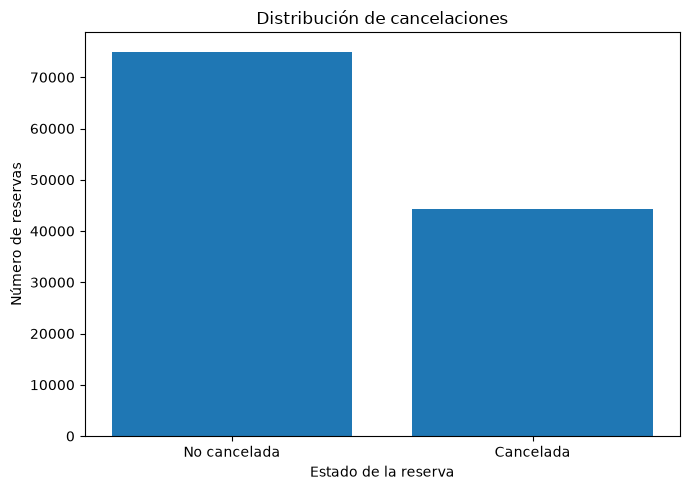

In [23]:
# ============================================================
# 20. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ============================================================

conteo_cancelaciones = df["is_canceled"].value_counts().sort_index()
porcentaje_cancelaciones = (
    df["is_canceled"].value_counts(normalize=True).sort_index() * 100
)

print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
print("=" * 50)

print(f"Reservas NO canceladas: {conteo_cancelaciones.get(0, 0):,}")
print(f"Reservas canceladas:    {conteo_cancelaciones.get(1, 0):,}")

print(f"\n% NO canceladas: {porcentaje_cancelaciones.get(0, 0):.2f}%")
print(f"% canceladas:    {porcentaje_cancelaciones.get(1, 0):.2f}%")

# Gráfico
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    ["No cancelada", "Cancelada"],
    [conteo_cancelaciones.get(0, 0),
     conteo_cancelaciones.get(1, 0)]
)

ax.set_title("Distribución de cancelaciones")
ax.set_ylabel("Número de reservas")
ax.set_xlabel("Estado de la reserva")

plt.tight_layout()
plt.show()

CANCELACIONES SEGÚN TIPO DE HOTEL


,Reservas,Cancelaciones,Tasa_cancelacion
hotel,,,
City Hotel,79163,33079,41.79
Resort Hotel,40047,11120,27.77


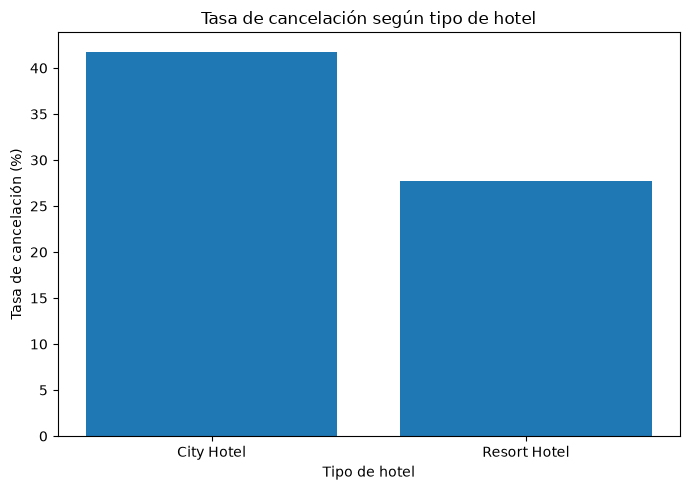

In [24]:
# ============================================================
# 21. CANCELACIONES SEGÚN TIPO DE HOTEL
# ============================================================

cancelacion_hotel = (
    df.groupby("hotel")["is_canceled"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

cancelacion_hotel.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

cancelacion_hotel["Tasa_cancelacion"] *= 100

print("CANCELACIONES SEGÚN TIPO DE HOTEL")
print("=" * 50)

display(cancelacion_hotel.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    cancelacion_hotel.index,
    cancelacion_hotel["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según tipo de hotel")
ax.set_xlabel("Tipo de hotel")
ax.set_ylabel("Tasa de cancelación (%)")

plt.tight_layout()
plt.show()

ANÁLISIS DE LEAD TIME

Resumen estadístico:


,count,mean,std,min,25%,50%,75%,max
is_canceled,,,,,,,,
0,75011.0,80.08,91.14,0.0,9.0,45.0,124.0,737.0
1,44199.0,144.89,118.61,0.0,49.0,113.0,214.0,629.0



Media y mediana de lead_time:


,mean,median
No cancelada,80.08,45.0
Cancelada,144.89,113.0



Tasa de cancelación según antelación:


,Reservas,Cancelaciones,Tasa_cancelacion
lead_time_group,,,
0-7 días,19635,1885,9.60
8-30 días,18945,5283,27.89
31-90 días,29529,11141,37.73
91-180 días,26420,11819,44.74
181-365 días,21534,11942,55.46
Más de 365 días,3147,2129,67.65


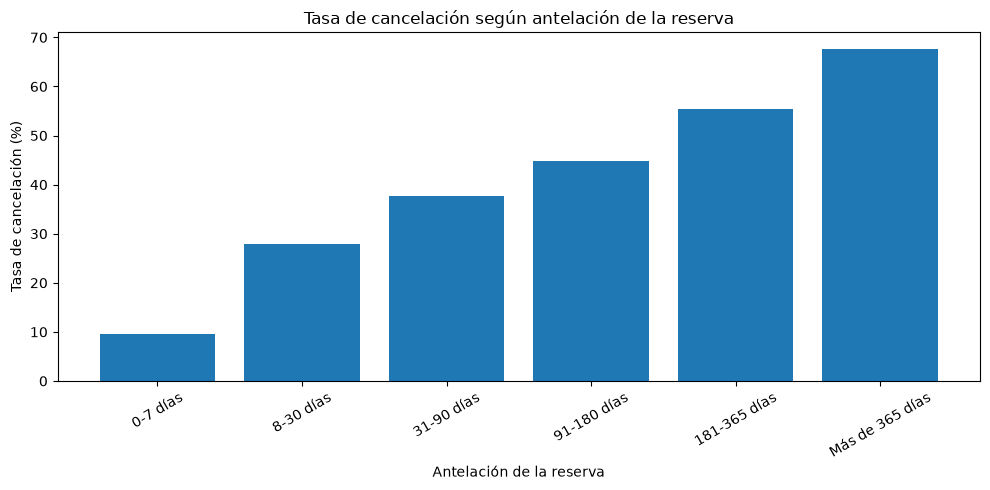

In [25]:
# ============================================================
# 22. RELACIÓN ENTRE LEAD TIME Y CANCELACIÓN
# ============================================================

print("ANÁLISIS DE LEAD TIME")
print("=" * 50)

print("\nResumen estadístico:")
display(
    df.groupby("is_canceled")["lead_time"]
      .describe()
      .round(2)
)

# Media y mediana
resumen_lead = (
    df.groupby("is_canceled")["lead_time"]
      .agg(["mean", "median"])
      .round(2)
)

resumen_lead.index = ["No cancelada", "Cancelada"]

print("\nMedia y mediana de lead_time:")
display(resumen_lead)

# Agrupamos el lead time en intervalos
bins = [-1, 7, 30, 90, 180, 365, float("inf")]
labels = [
    "0-7 días",
    "8-30 días",
    "31-90 días",
    "91-180 días",
    "181-365 días",
    "Más de 365 días"
]

df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=bins,
    labels=labels
)

lead_cancelacion = (
    df.groupby("lead_time_group", observed=False)["is_canceled"]
      .agg(["count", "sum", "mean"])
)

lead_cancelacion.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

lead_cancelacion["Tasa_cancelacion"] *= 100

print("\nTasa de cancelación según antelación:")
display(lead_cancelacion.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    lead_cancelacion.index.astype(str),
    lead_cancelacion["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según antelación de la reserva")
ax.set_xlabel("Antelación de la reserva")
ax.set_ylabel("Tasa de cancelación (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

CANCELACIONES SEGÚN TIPO DE DEPÓSITO


,Reservas,Cancelaciones,Tasa_cancelacion
deposit_type,,,
Non Refund,14587,14494,99.36
No Deposit,104461,29669,28.40
Refundable,162,36,22.22


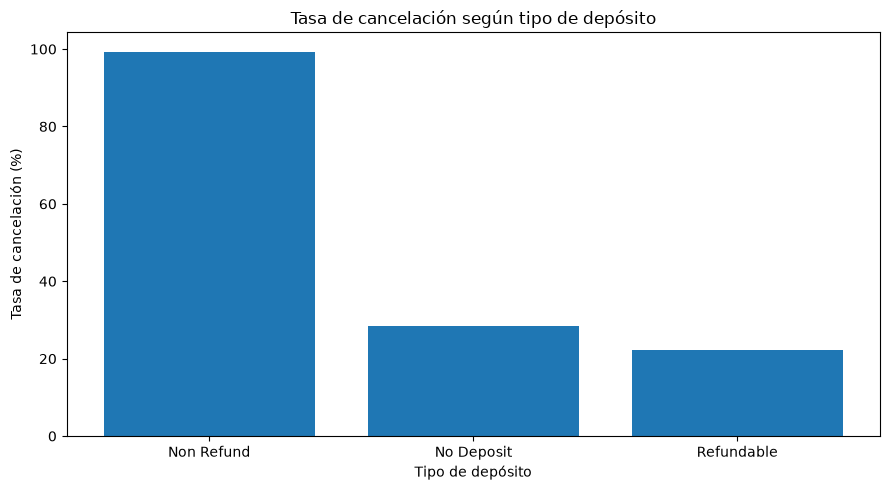

In [26]:
# ============================================================
# 23. CANCELACIONES SEGÚN TIPO DE DEPÓSITO
# ============================================================

deposito = (
    df.groupby("deposit_type")["is_canceled"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

deposito.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

deposito["Tasa_cancelacion"] *= 100

print("CANCELACIONES SEGÚN TIPO DE DEPÓSITO")
print("=" * 55)

display(deposito.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    deposito.index,
    deposito["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según tipo de depósito")
ax.set_xlabel("Tipo de depósito")
ax.set_ylabel("Tasa de cancelación (%)")

plt.tight_layout()
plt.show()

CANCELACIONES SEGÚN SEGMENTO DE MERCADO


,Reservas,Cancelaciones,Tasa_cancelacion
market_segment,,,
Undefined,2,2,100.00
Groups,19791,12094,61.11
Online TA,56408,20735,36.76
Offline TA/TO,24182,8302,34.33
Aviation,235,52,22.13
Corporate,5282,991,18.76
Direct,12582,1934,15.37
Complementary,728,89,12.23


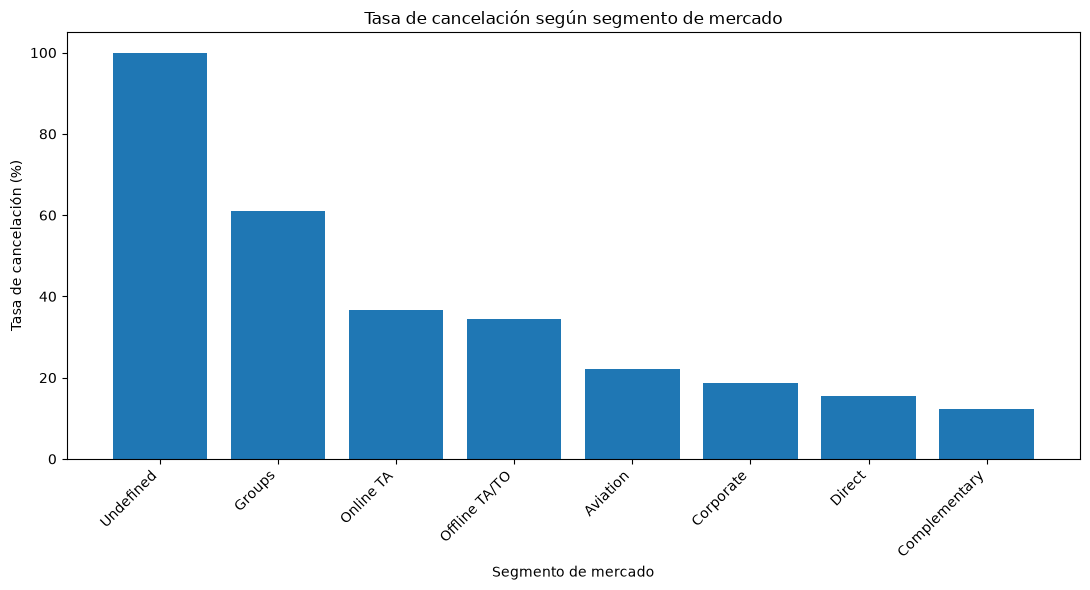

In [27]:
# ============================================================
# 24. CANCELACIONES SEGÚN SEGMENTO DE MERCADO
# ============================================================

segmento = (
    df.groupby("market_segment")["is_canceled"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

segmento.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

segmento["Tasa_cancelacion"] *= 100

print("CANCELACIONES SEGÚN SEGMENTO DE MERCADO")
print("=" * 55)

display(segmento.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    segmento.index,
    segmento["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según segmento de mercado")
ax.set_xlabel("Segmento de mercado")
ax.set_ylabel("Tasa de cancelación (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

HISTORIAL DE CANCELACIONES PREVIAS

Resumen de previous_cancellations:


count    119210.00
mean          0.09
std           0.84
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          26.00
Name: previous_cancellations, dtype: float64


Tasa de cancelación según historial:


,Reservas,Cancelaciones,Tasa_cancelacion
previous_cancel_group,,,
Con cancelaciones previas,6479,5940,91.68
Sin cancelaciones previas,112731,38259,33.94



Detalle por número de cancelaciones previas:


,Reservas,Cancelaciones,Tasa_cancelacion
previous_cancellations,,,
0,112731,38259,33.94
1,6048,5712,94.44
2,114,38,33.33
3,65,20,30.77
4,31,7,22.58
5,19,2,10.53
6,22,7,31.82
11,35,10,28.57
13,12,11,91.67


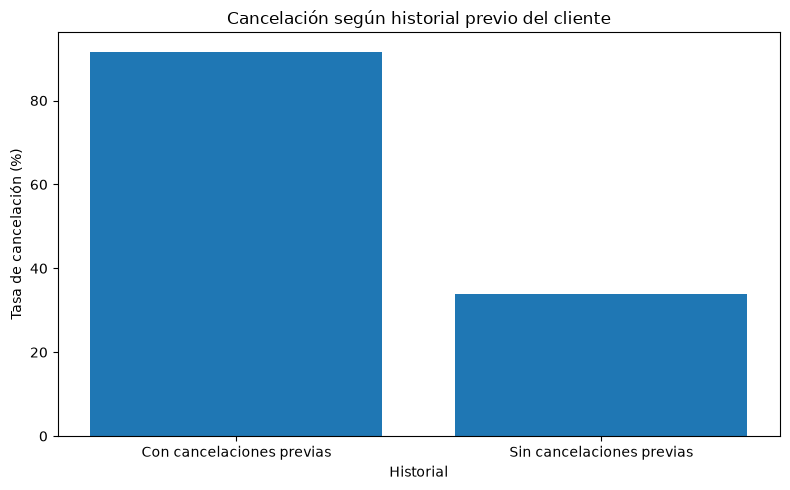

In [28]:
# ============================================================
# 25. HISTORIAL DE CANCELACIONES PREVIAS
# ============================================================

print("HISTORIAL DE CANCELACIONES PREVIAS")
print("=" * 55)

print("\nResumen de previous_cancellations:")
display(df["previous_cancellations"].describe().round(2))

# Creamos únicamente para el EDA dos grupos:
# clientes sin cancelaciones previas y con cancelaciones previas
df["previous_cancel_group"] = np.where(
    df["previous_cancellations"] > 0,
    "Con cancelaciones previas",
    "Sin cancelaciones previas"
)

historial = (
    df.groupby("previous_cancel_group")["is_canceled"]
      .agg(["count", "sum", "mean"])
)

historial.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

historial["Tasa_cancelacion"] *= 100

print("\nTasa de cancelación según historial:")
display(historial.round(2))

# Análisis detallado por número de cancelaciones previas
detalle_previas = (
    df.groupby("previous_cancellations")["is_canceled"]
      .agg(["count", "sum", "mean"])
)

detalle_previas.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

detalle_previas["Tasa_cancelacion"] *= 100

print("\nDetalle por número de cancelaciones previas:")
display(detalle_previas.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    historial.index,
    historial["Tasa_cancelacion"]
)

ax.set_title("Cancelación según historial previo del cliente")
ax.set_xlabel("Historial")
ax.set_ylabel("Tasa de cancelación (%)")

plt.tight_layout()
plt.show()

CAMBIO DE TIPO DE HABITACIÓN

Número de reservas según cambio de habitación:
room_changed
0    104414
1     14796
Name: count, dtype: int64

Porcentaje:
room_changed
0    87.59
1    12.41
Name: proportion, dtype: float64

Tasa de cancelación según cambio de habitación:


,Reservas,Cancelaciones,Tasa_cancelacion
room_changed,,,
Misma habitación,104414,43398,41.56
Habitación diferente,14796,801,5.41


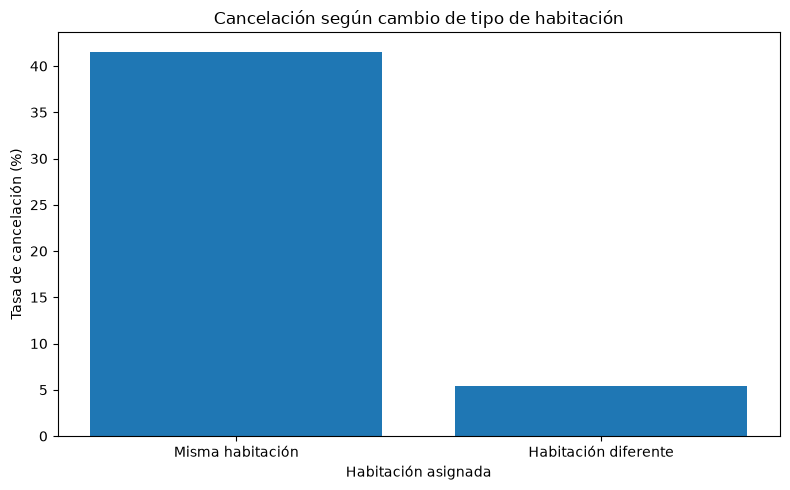

In [29]:
# ============================================================
# 26. CAMBIO ENTRE HABITACIÓN RESERVADA Y ASIGNADA
# ============================================================

print("CAMBIO DE TIPO DE HABITACIÓN")
print("=" * 55)

# Creamos una variable auxiliar:
# 0 = misma habitación
# 1 = habitación asignada distinta de la reservada
df["room_changed"] = (
    df["reserved_room_type"] != df["assigned_room_type"]
).astype(int)

print("\nNúmero de reservas según cambio de habitación:")
print(df["room_changed"].value_counts())

print("\nPorcentaje:")
print((df["room_changed"].value_counts(normalize=True) * 100).round(2))

# Relación con cancelaciones
habitacion = (
    df.groupby("room_changed")["is_canceled"]
      .agg(["count", "sum", "mean"])
)

habitacion.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

habitacion["Tasa_cancelacion"] *= 100

habitacion.index = habitacion.index.map({
    0: "Misma habitación",
    1: "Habitación diferente"
})

print("\nTasa de cancelación según cambio de habitación:")
display(habitacion.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    habitacion.index,
    habitacion["Tasa_cancelacion"]
)

ax.set_title("Cancelación según cambio de tipo de habitación")
ax.set_xlabel("Habitación asignada")
ax.set_ylabel("Tasa de cancelación (%)")

plt.tight_layout()
plt.show()

CAMBIOS REALIZADOS EN LA RESERVA

Resumen de booking_changes:


count    119210.00
mean          0.22
std           0.64
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          18.00
Name: booking_changes, dtype: float64


Tasa de cancelación según cambios realizados:


,Reservas,Cancelaciones,Tasa_cancelacion
booking_changes_group,,,
Sin cambios,101232,41369,40.87
1 cambio,12666,1804,14.24
2 cambios,3780,766,20.26
3 o más cambios,1532,260,16.97


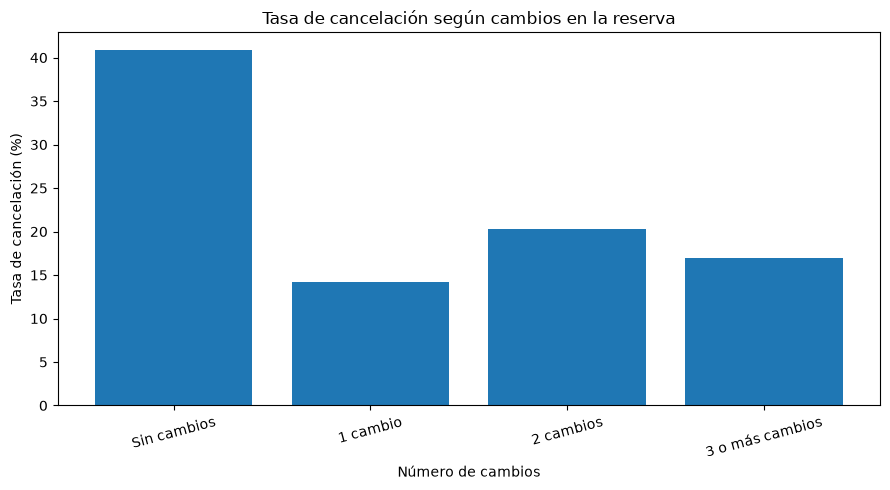

In [30]:
# ============================================================
# 27. ANÁLISIS DE CAMBIOS EN LA RESERVA
# ============================================================

print("CAMBIOS REALIZADOS EN LA RESERVA")
print("=" * 55)

print("\nResumen de booking_changes:")
display(df["booking_changes"].describe().round(2))

# Creamos grupos para facilitar la interpretación
df["booking_changes_group"] = pd.cut(
    df["booking_changes"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=[
        "Sin cambios",
        "1 cambio",
        "2 cambios",
        "3 o más cambios"
    ]
)

cambios = (
    df.groupby(
        "booking_changes_group",
        observed=True
    )["is_canceled"]
    .agg(["count", "sum", "mean"])
)

cambios.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

cambios["Tasa_cancelacion"] *= 100

print("\nTasa de cancelación según cambios realizados:")
display(cambios.round(2))

# Gráfico
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    cambios.index.astype(str),
    cambios["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según cambios en la reserva")
ax.set_xlabel("Número de cambios")
ax.set_ylabel("Tasa de cancelación (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

CANCELACIONES SEGÚN TIPO DE CLIENTE

Resultados por tipo de cliente:


,Reservas,Cancelaciones,Tasa_cancelacion
customer_type,,,
Transient,89476,36494,40.79
Contract,4072,1262,30.99
Transient-Party,25088,6385,25.45
Group,574,58,10.10



Distribución de tipos de cliente (%):


,Porcentaje
customer_type,
Transient,75.06
Transient-Party,21.05
Contract,3.42
Group,0.48


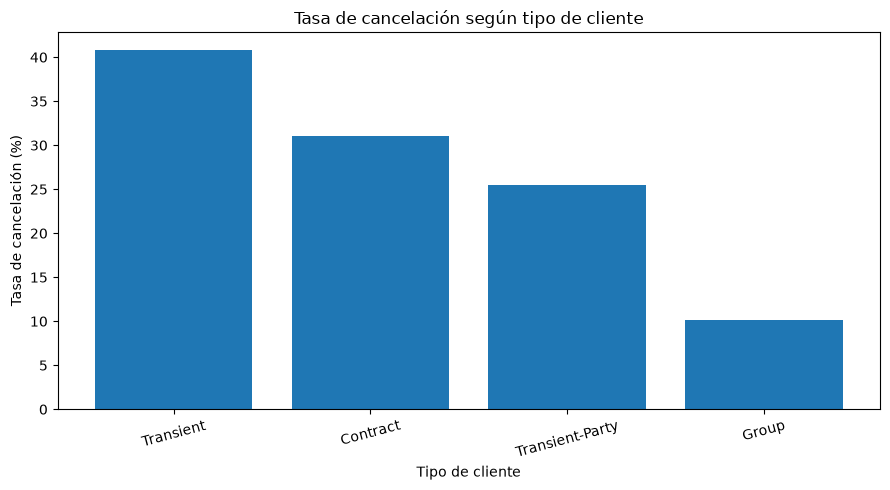

In [31]:
# ============================================================
# 28. CANCELACIONES SEGÚN TIPO DE CLIENTE
# ============================================================

print("CANCELACIONES SEGÚN TIPO DE CLIENTE")
print("=" * 55)

customer_analysis = (
    df.groupby("customer_type")["is_canceled"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

customer_analysis.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

customer_analysis["Tasa_cancelacion"] *= 100

print("\nResultados por tipo de cliente:")
display(customer_analysis.round(2))

# Porcentaje de reservas de cada tipo
print("\nDistribución de tipos de cliente (%):")
display(
    (df["customer_type"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Porcentaje")
)

# Gráfico
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    customer_analysis.index,
    customer_analysis["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según tipo de cliente")
ax.set_xlabel("Tipo de cliente")
ax.set_ylabel("Tasa de cancelación (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

CANCELACIONES SEGÚN MES DE LLEGADA

Resultados por mes:


,Reservas,Cancelaciones,Tasa_cancelacion
arrival_date_month,,,
January,5921,1806,30.50
February,8052,2693,33.45
March,9768,3148,32.23
April,11078,4518,40.78
May,11780,4677,39.70
June,10929,4534,41.49
July,12644,4737,37.46
August,13861,5237,37.78
September,10500,4115,39.19



Mes con mayor tasa de cancelación: June (41.49%)
Mes con menor tasa de cancelación: January (30.50%)


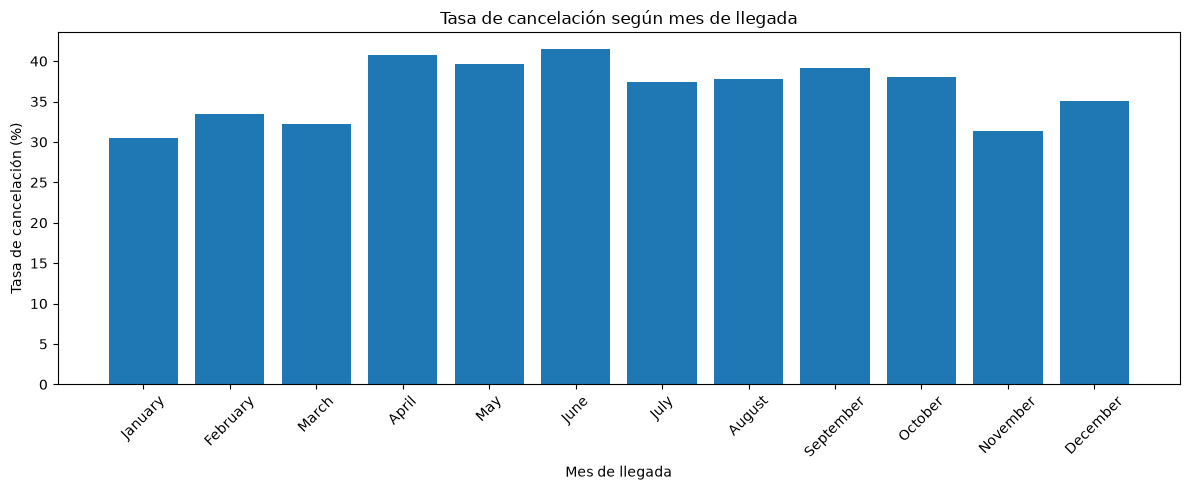

In [32]:
# ============================================================
# 29. CANCELACIONES SEGÚN MES DE LLEGADA
# ============================================================

print("CANCELACIONES SEGÚN MES DE LLEGADA")
print("=" * 55)

# Orden cronológico de los meses
orden_meses = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

meses = (
    df.groupby("arrival_date_month", observed=True)["is_canceled"]
      .agg(["count", "sum", "mean"])
)

meses.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

meses["Tasa_cancelacion"] *= 100

# Reordenamos cronológicamente
meses = meses.reindex(orden_meses)

print("\nResultados por mes:")
display(meses.round(2))

# Identificamos máximo y mínimo
mes_max = meses["Tasa_cancelacion"].idxmax()
mes_min = meses["Tasa_cancelacion"].idxmin()

print(
    f"\nMes con mayor tasa de cancelación: "
    f"{mes_max} ({meses.loc[mes_max, 'Tasa_cancelacion']:.2f}%)"
)

print(
    f"Mes con menor tasa de cancelación: "
    f"{mes_min} ({meses.loc[mes_min, 'Tasa_cancelacion']:.2f}%)"
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    meses.index,
    meses["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según mes de llegada")
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("Tasa de cancelación (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

CANCELACIONES SEGÚN CANAL DE DISTRIBUCIÓN


,Reservas,Cancelaciones,Tasa_cancelacion
distribution_channel,,,
Undefined,5,4,80.00
TA/TO,97750,40136,41.06
Corporate,6651,1467,22.06
GDS,193,37,19.17
Direct,14611,2555,17.49



Canal con mayor tasa de cancelación: TA/TO (41.06%)


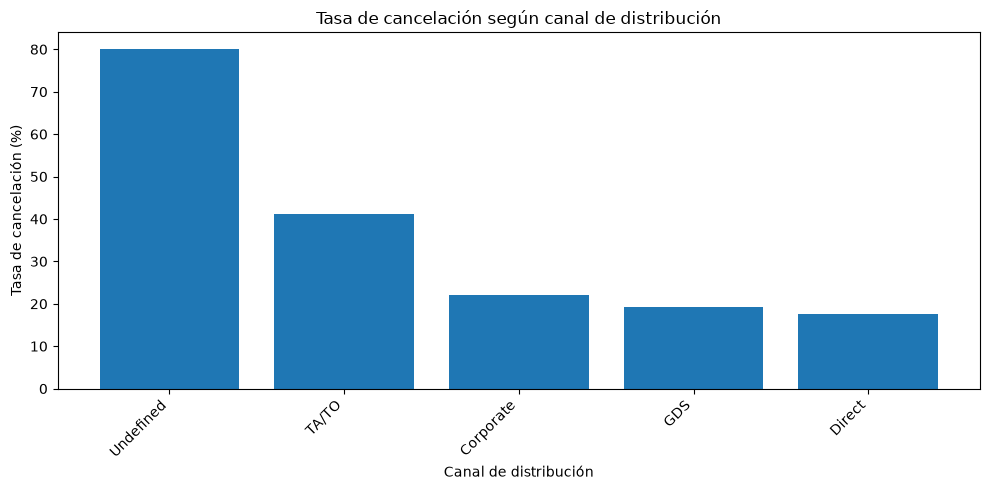


INSIGHT DE NEGOCIO
------------------------------------------------------------
El canal TA/TO presenta la mayor tasa de cancelación. Revenue Management debería considerar el canal de procedencia al definir acciones preventivas y políticas de reserva, evitando aplicar una misma estrategia a todos los canales.


In [33]:
# ============================================================
# CANCELACIONES SEGÚN CANAL DE DISTRIBUCIÓN
# ============================================================

canal = (
    df.groupby("distribution_channel")["is_canceled"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

canal.columns = [
    "Reservas",
    "Cancelaciones",
    "Tasa_cancelacion"
]

canal["Tasa_cancelacion"] *= 100

print("CANCELACIONES SEGÚN CANAL DE DISTRIBUCIÓN")
print("=" * 60)
display(canal.round(2))

# Excluimos categorías con muy pocas observaciones para evitar
# conclusiones de negocio basadas en muestras no representativas.
canal_relevante = canal[canal["Reservas"] >= 100]

canal_mayor = canal_relevante["Tasa_cancelacion"].idxmax()
tasa_mayor = canal_relevante.loc[canal_mayor, "Tasa_cancelacion"]

print(
    f"\nCanal con mayor tasa de cancelación: "
    f"{canal_mayor} ({tasa_mayor:.2f}%)"
)

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    canal.index.astype(str),
    canal["Tasa_cancelacion"]
)

ax.set_title("Tasa de cancelación según canal de distribución")
ax.set_xlabel("Canal de distribución")
ax.set_ylabel("Tasa de cancelación (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nINSIGHT DE NEGOCIO")
print("-" * 60)
print(
    f"El canal {canal_mayor} presenta la mayor tasa de cancelación. "
    "Revenue Management debería considerar el canal de procedencia "
    "al definir acciones preventivas y políticas de reserva, evitando "
    "aplicar una misma estrategia a todos los canales."
)

ADR SEGÚN ESTADO DE LA RESERVA


,Reservas,ADR_medio,ADR_mediano
No cancelada,74812,100.37,93.0
Cancelada,44167,104.96,96.3



ADR medio reservas no canceladas: 100.37 €
ADR medio reservas canceladas:    104.96 €
Diferencia:                        4.59 €
Diferencia porcentual:             4.58%


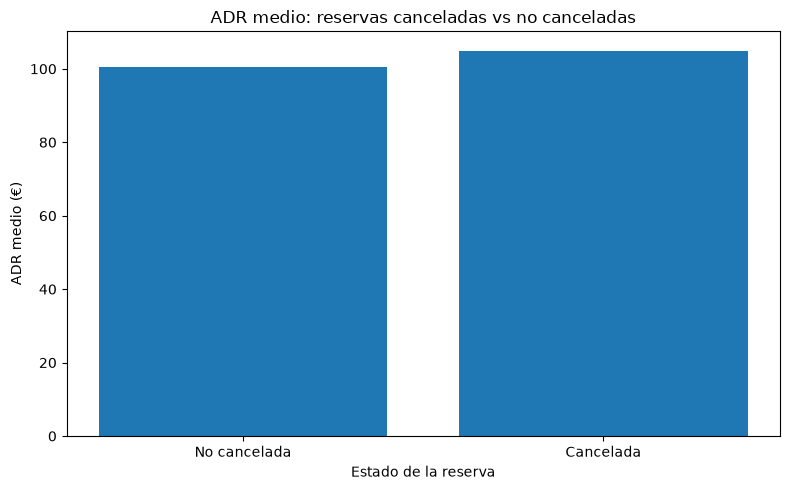


INSIGHT DE NEGOCIO
------------------------------------------------------------
Las reservas canceladas presentan un ADR medio 4.58% superior al de las reservas no canceladas. Esto indica que determinadas reservas de mayor valor económico también pueden estar expuestas a riesgo de cancelación. Identificarlas con antelación permitiría priorizar medidas preventivas en reservas cuyo impacto potencial sobre los ingresos sea mayor.


In [34]:
# ============================================================
# ADR MEDIO: RESERVAS CANCELADAS VS NO CANCELADAS
# ============================================================

adr_cancelacion = (
    df.groupby("is_canceled")["adr"]
      .agg(["count", "mean", "median"])
)

adr_cancelacion.index = ["No cancelada", "Cancelada"]
adr_cancelacion.columns = ["Reservas", "ADR_medio", "ADR_mediano"]

print("ADR SEGÚN ESTADO DE LA RESERVA")
print("=" * 60)
display(adr_cancelacion.round(2))

adr_no_canceladas = adr_cancelacion.loc["No cancelada", "ADR_medio"]
adr_canceladas = adr_cancelacion.loc["Cancelada", "ADR_medio"]

diferencia_adr = adr_canceladas - adr_no_canceladas
diferencia_pct = (diferencia_adr / adr_no_canceladas) * 100

print(f"\nADR medio reservas no canceladas: {adr_no_canceladas:.2f} €")
print(f"ADR medio reservas canceladas:    {adr_canceladas:.2f} €")
print(f"Diferencia:                        {diferencia_adr:.2f} €")
print(f"Diferencia porcentual:             {diferencia_pct:.2f}%")

# Gráfico
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    adr_cancelacion.index,
    adr_cancelacion["ADR_medio"]
)

ax.set_title("ADR medio: reservas canceladas vs no canceladas")
ax.set_xlabel("Estado de la reserva")
ax.set_ylabel("ADR medio (€)")

plt.tight_layout()
plt.show()

print("\nINSIGHT DE NEGOCIO")
print("-" * 60)

if adr_canceladas > adr_no_canceladas:
    print(
        f"Las reservas canceladas presentan un ADR medio "
        f"{abs(diferencia_pct):.2f}% superior al de las reservas no canceladas. "
        "Esto indica que determinadas reservas de mayor valor económico también "
        "pueden estar expuestas a riesgo de cancelación. Identificarlas con "
        "antelación permitiría priorizar medidas preventivas en reservas cuyo "
        "impacto potencial sobre los ingresos sea mayor."
    )
else:
    print(
        f"Las reservas canceladas presentan un ADR medio "
        f"{abs(diferencia_pct):.2f}% inferior al de las reservas no canceladas. "
        "Por tanto, el precio debe analizarse conjuntamente con otras variables "
        "de la reserva antes de definir acciones preventivas."
    )

## Feature Engineering

A partir de las variables originales se crea `total_guests`, definida como la suma de adultos, niños y bebés incluidos en la reserva.

Desde una perspectiva de negocio, el tamaño total del grupo puede influir en el comportamiento de cancelación, ya que las reservas de grupos más numerosos implican mayor coordinación, coste y planificación. Incorporar esta información permite al modelo representar de forma directa el tamaño de la reserva sin depender de interpretar por separado `adults`, `children` y `babies`.

In [35]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

# Número total de huéspedes incluidos en la reserva
df["total_guests"] = (
    df["adults"]
    + df["children"].fillna(0)
    + df["babies"]
)

print("Nueva variable creada: total_guests")
print("=" * 60)

display(
    df[
        ["adults", "children", "babies", "total_guests", "is_canceled"]
    ].head()
)

print("\nResumen de total_guests:")
display(df["total_guests"].describe().round(2))

print("\nTasa de cancelación según tamaño del grupo:")
display(
    df.groupby("total_guests")["is_canceled"]
      .agg(Reservas="count", Tasa_cancelacion="mean")
      .assign(Tasa_cancelacion=lambda x: x["Tasa_cancelacion"] * 100)
      .round(2)
)

Nueva variable creada: total_guests


,adults,children,babies,total_guests,is_canceled
0,2,0.0,0,2.0,0
1,2,0.0,0,2.0,0
2,1,0.0,0,1.0,0
3,1,0.0,0,1.0,0
4,2,0.0,0,2.0,0



Resumen de total_guests:


count    119210.00
mean          1.97
std           0.72
min           1.00
25%           2.00
50%           2.00
75%           2.00
max          55.00
Name: total_guests, dtype: float64


Tasa de cancelación según tamaño del grupo:


,Reservas,Tasa_cancelacion
total_guests,,
1.0,22581,29.03
2.0,82051,39.70
3.0,10495,32.18
4.0,3929,41.89
5.0,137,24.82
6.0,1,100.00
10.0,2,50.00
12.0,2,50.00
20.0,2,100.00


In [36]:
# ============================================================
# 30. AUDITORÍA FINAL DE VARIABLES PARA MACHINE LEARNING
# ============================================================

print("AUDITORÍA DE VARIABLES")
print("=" * 65)

print(f"\nNúmero de registros: {len(df):,}")
print(f"Número de variables actuales: {df.shape[1]}")

print("\nVariables disponibles actualmente:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

# ------------------------------------------------------------
# Variables que pueden provocar DATA LEAKAGE
# ------------------------------------------------------------

posible_leakage = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type"
]

leakage_presentes = [
    col for col in posible_leakage
    if col in df.columns
]

print("\n" + "=" * 65)
print("VARIABLES A EXCLUIR POR POSIBLE DATA LEAKAGE")
print("=" * 65)

if leakage_presentes:
    for col in leakage_presentes:
        print(f"❌ {col}")
else:
    print("No se encontraron variables de leakage de esta lista.")

# ------------------------------------------------------------
# Variables auxiliares creadas durante el EDA
# ------------------------------------------------------------

variables_auxiliares = [
    "lead_time_group",
    "previous_cancel_group",
    "room_changed",
    "booking_changes_group"
]

aux_presentes = [
    col for col in variables_auxiliares
    if col in df.columns
]

print("\nVariables auxiliares creadas durante el EDA:")

if aux_presentes:
    for col in aux_presentes:
        print(f"⚠️ {col}")
else:
    print("No hay variables auxiliares.")

# ------------------------------------------------------------
# Variable objetivo
# ------------------------------------------------------------

print("\nVariable objetivo:")
print("🎯 is_canceled")

print("\n" + "=" * 65)
print("AUDITORÍA COMPLETADA")
print("=" * 65)

AUDITORÍA DE VARIABLES

Número de registros: 119,210
Número de variables actuales: 36

Variables disponibles actualmente:
01. hotel
02. is_canceled
03. lead_time
04. arrival_date_year
05. arrival_date_month
06. arrival_date_week_number
07. arrival_date_day_of_month
08. stays_in_weekend_nights
09. stays_in_week_nights
10. adults
11. children
12. babies
13. meal
14. country
15. market_segment
16. distribution_channel
17. is_repeated_guest
18. previous_cancellations
19. previous_bookings_not_canceled
20. reserved_room_type
21. assigned_room_type
22. booking_changes
23. deposit_type
24. agent
25. days_in_waiting_list
26. customer_type
27. adr
28. required_car_parking_spaces
29. total_of_special_requests
30. reservation_status
31. reservation_status_date
32. lead_time_group
33. previous_cancel_group
34. room_changed
35. booking_changes_group
36. total_guests

VARIABLES A EXCLUIR POR POSIBLE DATA LEAKAGE
❌ reservation_status
❌ reservation_status_date
❌ assigned_room_type

Variables auxiliare

In [37]:
# ============================================================
# PREPARACIÓN DE VARIABLES PARA MACHINE LEARNING
# ============================================================

# Variable objetivo
y = df["is_canceled"].copy()

# Variables que NO deben entrar como predictores
columnas_excluir = [
    "is_canceled",              # Variable objetivo
    "reservation_status",       # Data leakage
    "reservation_status_date",  # Información posterior
    "assigned_room_type",       # Puede conocerse después de reservar

    # Variables creadas únicamente para el EDA
    "lead_time_group",
    "previous_cancel_group",
    "room_changed",
    "booking_changes_group"
]

# Solo eliminamos las que realmente existen
columnas_excluir_presentes = [
    col for col in columnas_excluir
    if col in df.columns
]

X = df.drop(columns=columnas_excluir_presentes).copy()

print("PREPARACIÓN DE X E y")
print("=" * 60)

print(f"Registros en X: {X.shape[0]:,}")
print(f"Variables predictoras: {X.shape[1]}")
print(f"Registros en y: {len(y):,}")

print("\nColumnas excluidas:")
for col in columnas_excluir_presentes:
    print(f"❌ {col}")

print("\nVariable objetivo:")
print("🎯 is_canceled")

print("\nDistribución de y:")
print(y.value_counts())

print("\nDistribución porcentual:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nComprobación:")
print(f"¿is_canceled está dentro de X?: {'is_canceled' in X.columns}")
print(f"¿Hay mismo número de filas en X e y?: {len(X) == len(y)}")

# ============================================================
# COMPROBACIÓN FINAL DE FEATURE ENGINEERING
# ============================================================

print("\nComprobación Feature Engineering:")
print(f"¿total_guests está dentro de X?: {'total_guests' in X.columns}")

if "total_guests" in X.columns:
    print("✅ total_guests se incorpora correctamente al modelo.")
else:
    print("❌ total_guests NO se está incorporando al modelo.")


# ============================================================
# COMPROBACIÓN FINAL DE DATA LEAKAGE
# ============================================================

variables_leakage = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type"
]

leakage_en_X = [
    col for col in variables_leakage
    if col in X.columns
]

print("\nComprobación final de Data Leakage:")
print("=" * 60)

if len(leakage_en_X) == 0:
    print("✅ Ninguna variable identificada como leakage está presente en X.")
    print("✅ El conjunto de predictores utiliza únicamente información disponible antes de conocer el resultado de la reserva.")
else:
    print("❌ ATENCIÓN: se han encontrado variables potencialmente problemáticas en X:")
    for col in leakage_en_X:
        print(f"   - {col}")

PREPARACIÓN DE X E y
Registros en X: 119,210
Variables predictoras: 28
Registros en y: 119,210

Columnas excluidas:
❌ is_canceled
❌ reservation_status
❌ reservation_status_date
❌ assigned_room_type
❌ lead_time_group
❌ previous_cancel_group
❌ room_changed
❌ booking_changes_group

Variable objetivo:
🎯 is_canceled

Distribución de y:
is_canceled
0    75011
1    44199
Name: count, dtype: int64

Distribución porcentual:
is_canceled
0    62.92
1    37.08
Name: proportion, dtype: float64

Comprobación:
¿is_canceled está dentro de X?: False
¿Hay mismo número de filas en X e y?: True

Comprobación Feature Engineering:
¿total_guests está dentro de X?: True
✅ total_guests se incorpora correctamente al modelo.

Comprobación final de Data Leakage:
✅ Ninguna variable identificada como leakage está presente en X.
✅ El conjunto de predictores utiliza únicamente información disponible antes de conocer el resultado de la reserva.


In [38]:
print("\nComprobación Feature Engineering:")
print(f"¿total_guests está dentro de X?: {'total_guests' in X.columns}")

if "total_guests" in X.columns:
    print("✅ total_guests se incorpora correctamente al modelo.")
else:
    print("❌ total_guests NO se está incorporando al modelo.")


Comprobación Feature Engineering:
¿total_guests está dentro de X?: True
✅ total_guests se incorpora correctamente al modelo.


In [39]:
# ============================================================
# TRAIN / TEST SPLIT TEMPORAL
# ============================================================

import pandas as pd

# Crear fecha completa de llegada a partir de las columnas originales
fecha_llegada = pd.to_datetime(
    df["arrival_date_year"].astype(str)
    + "-"
    + df["arrival_date_month"].astype(str)
    + "-"
    + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)

# Ordenar cronológicamente los registros
orden_temporal = fecha_llegada.sort_values().index

X_temporal = X.loc[orden_temporal]
y_temporal = y.loc[orden_temporal]
fecha_temporal = fecha_llegada.loc[orden_temporal]

# 80 % de las reservas más antiguas para entrenamiento
# 20 % de las reservas más recientes para test
punto_corte = int(len(X_temporal) * 0.80)

X_train = X_temporal.iloc[:punto_corte].copy()
X_test = X_temporal.iloc[punto_corte:].copy()

y_train = y_temporal.iloc[:punto_corte].copy()
y_test = y_temporal.iloc[punto_corte:].copy()

fecha_train = fecha_temporal.iloc[:punto_corte]
fecha_test = fecha_temporal.iloc[punto_corte:]

print("DIVISIÓN TEMPORAL TRAIN / TEST")
print("=" * 60)

print(f"Dataset completo: {len(X):,} registros")

print("\nTRAIN")
print(f"Registros: {len(X_train):,}")
print(f"Porcentaje: {len(X_train) / len(X) * 100:.2f}%")
print(f"Periodo: {fecha_train.min().date()} -> {fecha_train.max().date()}")

print("\nTEST")
print(f"Registros: {len(X_test):,}")
print(f"Porcentaje: {len(X_test) / len(X) * 100:.2f}%")
print(f"Periodo: {fecha_test.min().date()} -> {fecha_test.max().date()}")

print("\nDistribución variable objetivo - TRAIN:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribución variable objetivo - TEST:")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nComprobaciones:")
print(f"Mismas columnas: {list(X_train.columns) == list(X_test.columns)}")
print(
    "Solapamiento de índices TRAIN/TEST:",
    len(set(X_train.index) & set(X_test.index))
)
print(
    "Separación temporal correcta:",
    fecha_train.max() <= fecha_test.min()
)

DIVISIÓN TEMPORAL TRAIN / TEST
Dataset completo: 119,210 registros

TRAIN
Registros: 95,368
Porcentaje: 80.00%
Periodo: 2015-07-01 -> 2017-04-22

TEST
Registros: 23,842
Porcentaje: 20.00%
Periodo: 2017-04-22 -> 2017-08-31

Distribución variable objetivo - TRAIN:
is_canceled
0    63.9
1    36.1
Name: proportion, dtype: float64

Distribución variable objetivo - TEST:
is_canceled
0    59.01
1    40.99
Name: proportion, dtype: float64

Comprobaciones:
Mismas columnas: True
Solapamiento de índices TRAIN/TEST: 0
Separación temporal correcta: True


In [40]:
# ============================================================
# PREPROCESAMIENTO DE VARIABLES
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Separar variables numéricas y categóricas
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("PREPROCESAMIENTO")
print("=" * 60)

print(f"\nVariables numéricas: {len(numeric_features)}")
for col in numeric_features:
    print(f"  - {col}")

print(f"\nVariables categóricas: {len(categorical_features)}")
for col in categorical_features:
    print(f"  - {col}")

# Pipeline para variables numéricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Unir ambos preprocesamientos
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\n" + "=" * 60)
print("Preprocesador creado correctamente.")
print("Todavía NO se ha ajustado sobre los datos.")

PREPROCESAMIENTO

Variables numéricas: 19
  - lead_time
  - arrival_date_year
  - arrival_date_week_number
  - arrival_date_day_of_month
  - stays_in_weekend_nights
  - stays_in_week_nights
  - adults
  - children
  - babies
  - is_repeated_guest
  - previous_cancellations
  - previous_bookings_not_canceled
  - booking_changes
  - agent
  - days_in_waiting_list
  - adr
  - required_car_parking_spaces
  - total_of_special_requests
  - total_guests

Variables categóricas: 9
  - hotel
  - arrival_date_month
  - meal
  - country
  - market_segment
  - distribution_channel
  - reserved_room_type
  - deposit_type
  - customer_type

Preprocesador creado correctamente.
Todavía NO se ha ajustado sobre los datos.


C:\Users\HP\AppData\Local\Temp\ipykernel_20192\2018805304.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


In [41]:
# ============================================================
# COMPROBACIÓN DEL PREPROCESAMIENTO
# ============================================================

print("COMPROBACIÓN DEL PREPROCESAMIENTO")
print("=" * 60)

print(f"Total variables antes del preprocesamiento: {X_train.shape[1]}")
print(f"Variables numéricas: {len(numeric_features)}")
print(f"Variables categóricas: {len(categorical_features)}")

print("\nComprobación de total_guests:")
print(f"¿Está total_guests en X_train?: {'total_guests' in X_train.columns}")
print(f"¿Está total_guests entre las variables numéricas?: {'total_guests' in numeric_features}")

print("\nControl de Data Leakage:")
variables_leakage = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type"
]

for variable in variables_leakage:
    print(f"{variable}: {'❌ PRESENTE' if variable in X_train.columns else '✅ EXCLUIDA'}")

COMPROBACIÓN DEL PREPROCESAMIENTO
Total variables antes del preprocesamiento: 28
Variables numéricas: 19
Variables categóricas: 9

Comprobación de total_guests:
¿Está total_guests en X_train?: True
¿Está total_guests entre las variables numéricas?: True

Control de Data Leakage:
reservation_status: ✅ EXCLUIDA
reservation_status_date: ✅ EXCLUIDA
assigned_room_type: ✅ EXCLUIDA


In [42]:
# ============================================================
# MODELO 1: REGRESIÓN LOGÍSTICA
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Pipeline completo:
# preprocesamiento + modelo
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("ENTRENAMIENTO - REGRESIÓN LOGÍSTICA")
print("=" * 60)

# Entrenamiento SOLO con TRAIN
logistic_model.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

# Predicciones sobre TEST
y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Predicciones realizadas sobre TEST.")

ENTRENAMIENTO - REGRESIÓN LOGÍSTICA
Modelo entrenado correctamente.
Predicciones realizadas sobre TEST.


In [43]:
# ============================================================
# EVALUACIÓN DEL MODELO 1: REGRESIÓN LOGÍSTICA
# ============================================================

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)
roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("EVALUACIÓN - REGRESIÓN LOGÍSTICA")
print("=" * 60)

print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nMATRIZ DE CONFUSIÓN")
print("=" * 60)

cm_logistic = confusion_matrix(y_test, y_pred_logistic)
print(cm_logistic)

print("\nINFORME DE CLASIFICACIÓN")
print("=" * 60)
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["No cancelada", "Cancelada"]
))

EVALUACIÓN - REGRESIÓN LOGÍSTICA
Accuracy:  0.7714 (77.14%)
Precision: 0.7168 (71.68%)
Recall:    0.7313 (73.13%)
F1-score:  0.7240
ROC-AUC:   0.8533

MATRIZ DE CONFUSIÓN
[[11245  2824]
 [ 2626  7147]]

INFORME DE CLASIFICACIÓN
              precision    recall  f1-score   support

No cancelada       0.81      0.80      0.80     14069
   Cancelada       0.72      0.73      0.72      9773

    accuracy                           0.77     23842
   macro avg       0.76      0.77      0.76     23842
weighted avg       0.77      0.77      0.77     23842



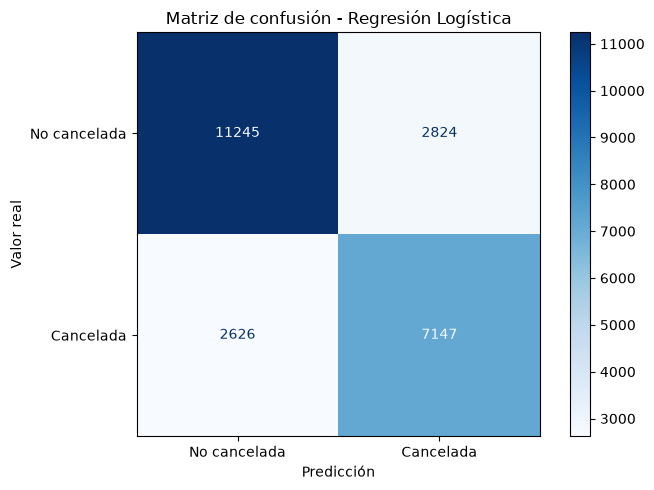

In [44]:
# ============================================================
# MATRIZ DE CONFUSIÓN - REGRESIÓN LOGÍSTICA
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["No cancelada", "Cancelada"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()

plt.show()

In [45]:
# ============================================================
# MODELO 2: RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("ENTRENAMIENTO - RANDOM FOREST")
print("=" * 60)

random_forest_model.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

# Predicciones
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Predicciones realizadas sobre TEST.")

ENTRENAMIENTO - RANDOM FOREST
Modelo entrenado correctamente.
Predicciones realizadas sobre TEST.


In [46]:
# ============================================================
# EVALUACIÓN DEL MODELO 2: RANDOM FOREST
# ============================================================

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("EVALUACIÓN - RANDOM FOREST")
print("=" * 60)

print(f"Accuracy:  {accuracy_rf:.4f} ({accuracy_rf*100:.2f}%)")
print(f"Precision: {precision_rf:.4f} ({precision_rf*100:.2f}%)")
print(f"Recall:    {recall_rf:.4f} ({recall_rf*100:.2f}%)")
print(f"F1-score:  {f1_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

print("\nMATRIZ DE CONFUSIÓN")
print("=" * 60)

cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

print("\nINFORME DE CLASIFICACIÓN")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No cancelada", "Cancelada"]
))

EVALUACIÓN - RANDOM FOREST
Accuracy:  0.7764 (77.64%)
Precision: 0.8353 (83.53%)
Recall:    0.5663 (56.63%)
F1-score:  0.6750
ROC-AUC:   0.8815

MATRIZ DE CONFUSIÓN
[[12978  1091]
 [ 4239  5534]]

INFORME DE CLASIFICACIÓN
              precision    recall  f1-score   support

No cancelada       0.75      0.92      0.83     14069
   Cancelada       0.84      0.57      0.67      9773

    accuracy                           0.78     23842
   macro avg       0.79      0.74      0.75     23842
weighted avg       0.79      0.78      0.77     23842



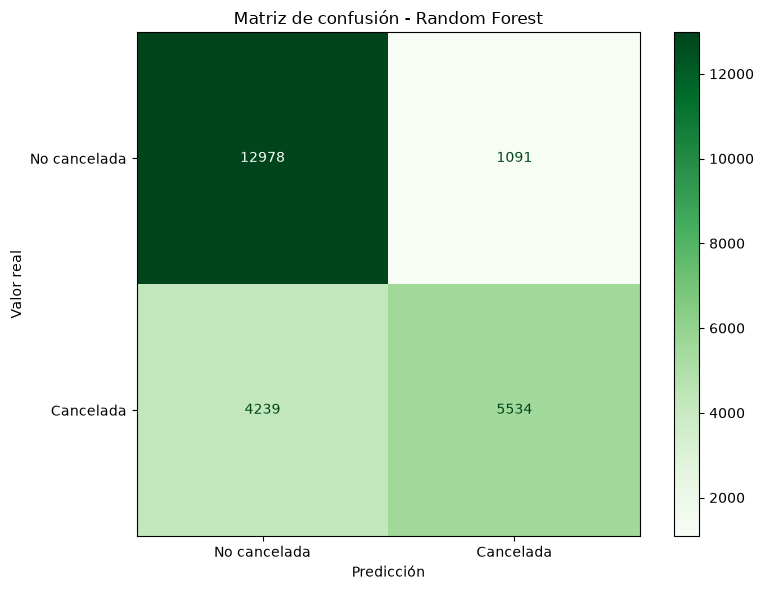

In [47]:
# ============================================================
# MATRIZ DE CONFUSIÓN - RANDOM FOREST
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No cancelada", "Cancelada"]
).plot(
    cmap="Greens",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

In [48]:
# ============================================================
# OPTIMIZACIÓN DE HIPERPARÁMETROS - RANDOM FOREST
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Pipeline: mismo preprocesamiento + Random Forest
rf_optimization_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Espacio de hiperparámetros
param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [10, 15, 20, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf_optimization_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("OPTIMIZACIÓN DE HIPERPARÁMETROS - RANDOM FOREST")
print("=" * 60)

print("\nIniciando RandomizedSearchCV...")

random_search.fit(X_train, y_train)

print("\nOptimización completada.")

print("\nMejores hiperparámetros:")
for parametro, valor in random_search.best_params_.items():
    print(f"  {parametro}: {valor}")

print(f"\nMejor ROC-AUC en validación: {random_search.best_score_:.4f}")

OPTIMIZACIÓN DE HIPERPARÁMETROS - RANDOM FOREST

Iniciando RandomizedSearchCV...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Optimización completada.

Mejores hiperparámetros:
  classifier__n_estimators: 300
  classifier__min_samples_split: 2
  classifier__min_samples_leaf: 4
  classifier__max_features: sqrt
  classifier__max_depth: None

Mejor ROC-AUC en validación: 0.9067


In [49]:
# ============================================================
# EVALUACIÓN DEL RANDOM FOREST OPTIMIZADO
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Recuperar el mejor modelo encontrado por RandomizedSearchCV
random_forest_optimized = random_search.best_estimator_

# Predicciones sobre el TEST temporal
y_pred_rf_opt = random_forest_optimized.predict(X_test)
y_prob_rf_opt = random_forest_optimized.predict_proba(X_test)[:, 1]

# Métricas
accuracy_rf_opt = accuracy_score(y_test, y_pred_rf_opt)
precision_rf_opt = precision_score(y_test, y_pred_rf_opt)
recall_rf_opt = recall_score(y_test, y_pred_rf_opt)
f1_rf_opt = f1_score(y_test, y_pred_rf_opt)
roc_auc_rf_opt = roc_auc_score(y_test, y_prob_rf_opt)

print("EVALUACIÓN - RANDOM FOREST OPTIMIZADO")
print("=" * 60)

print(f"Accuracy:  {accuracy_rf_opt:.4f} ({accuracy_rf_opt*100:.2f}%)")
print(f"Precision: {precision_rf_opt:.4f} ({precision_rf_opt*100:.2f}%)")
print(f"Recall:    {recall_rf_opt:.4f} ({recall_rf_opt*100:.2f}%)")
print(f"F1-score:  {f1_rf_opt:.4f}")
print(f"ROC-AUC:   {roc_auc_rf_opt:.4f}")

print("\nMATRIZ DE CONFUSIÓN")
print("=" * 60)

cm_rf_opt = confusion_matrix(y_test, y_pred_rf_opt)
print(cm_rf_opt)

print("\nINFORME DE CLASIFICACIÓN")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_rf_opt,
    target_names=["No cancelada", "Cancelada"]
))

EVALUACIÓN - RANDOM FOREST OPTIMIZADO
Accuracy:  0.7806 (78.06%)
Precision: 0.8370 (83.70%)
Recall:    0.5771 (57.71%)
F1-score:  0.6832
ROC-AUC:   0.8845

MATRIZ DE CONFUSIÓN
[[12971  1098]
 [ 4133  5640]]

INFORME DE CLASIFICACIÓN
              precision    recall  f1-score   support

No cancelada       0.76      0.92      0.83     14069
   Cancelada       0.84      0.58      0.68      9773

    accuracy                           0.78     23842
   macro avg       0.80      0.75      0.76     23842
weighted avg       0.79      0.78      0.77     23842



In [50]:
# ============================================================
# GESTIÓN DEL DESBALANCEO - RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Modelo utilizando los hiperparámetros optimizados
# y ponderación automática de las clases
rf_balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("GESTIÓN DEL DESBALANCEO")
print("=" * 60)

print("\nDistribución de clases en TRAIN:")
print(y_train.value_counts())
print("\nPorcentaje:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print(
    "\nSe utiliza class_weight='balanced' para asignar mayor peso "
    "a la clase minoritaria durante el entrenamiento."
)

# Entrenamiento
rf_balanced_model.fit(X_train, y_train)

# Predicciones
y_pred_rf_bal = rf_balanced_model.predict(X_test)
y_prob_rf_bal = rf_balanced_model.predict_proba(X_test)[:, 1]

print("\nModelo entrenado correctamente.")

GESTIÓN DEL DESBALANCEO

Distribución de clases en TRAIN:
is_canceled
0    60942
1    34426
Name: count, dtype: int64

Porcentaje:
is_canceled
0    63.9
1    36.1
Name: proportion, dtype: float64

Se utiliza class_weight='balanced' para asignar mayor peso a la clase minoritaria durante el entrenamiento.

Modelo entrenado correctamente.


In [51]:
# ============================================================
# EVALUACIÓN - RANDOM FOREST BALANCEADO
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Métricas
accuracy_rf_bal = accuracy_score(y_test, y_pred_rf_bal)
precision_rf_bal = precision_score(y_test, y_pred_rf_bal)
recall_rf_bal = recall_score(y_test, y_pred_rf_bal)
f1_rf_bal = f1_score(y_test, y_pred_rf_bal)
roc_auc_rf_bal = roc_auc_score(y_test, y_prob_rf_bal)

# Matriz de confusión
cm_rf_bal = confusion_matrix(y_test, y_pred_rf_bal)

print("EVALUACIÓN - RANDOM FOREST BALANCEADO")
print("=" * 60)

print(f"Accuracy:  {accuracy_rf_bal:.4f} ({accuracy_rf_bal * 100:.2f}%)")
print(f"Precision: {precision_rf_bal:.4f} ({precision_rf_bal * 100:.2f}%)")
print(f"Recall:    {recall_rf_bal:.4f} ({recall_rf_bal * 100:.2f}%)")
print(f"F1-score:  {f1_rf_bal:.4f}")
print(f"ROC-AUC:   {roc_auc_rf_bal:.4f}")

print("\nMATRIZ DE CONFUSIÓN")
print("=" * 60)
print(cm_rf_bal)

print("\nINFORME DE CLASIFICACIÓN")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_rf_bal,
        target_names=["No cancelada", "Cancelada"]
    )
)

EVALUACIÓN - RANDOM FOREST BALANCEADO
Accuracy:  0.7941 (79.41%)
Precision: 0.8007 (80.07%)
Recall:    0.6625 (66.25%)
F1-score:  0.7251
ROC-AUC:   0.8856

MATRIZ DE CONFUSIÓN
[[12457  1612]
 [ 3298  6475]]

INFORME DE CLASIFICACIÓN
              precision    recall  f1-score   support

No cancelada       0.79      0.89      0.84     14069
   Cancelada       0.80      0.66      0.73      9773

    accuracy                           0.79     23842
   macro avg       0.80      0.77      0.78     23842
weighted avg       0.79      0.79      0.79     23842



COMPARACIÓN FINAL DE MODELOS
             Modelo  Accuracy  Precision  Recall  F1-score  ROC-AUC
Regresión Logística    0.7714     0.7168  0.7313    0.7240   0.8533
      Random Forest    0.7764     0.8353  0.5663    0.6750   0.8815
      RF Optimizado    0.7806     0.8370  0.5771    0.6832   0.8845
      RF Balanceado    0.7941     0.8007  0.6625    0.7251   0.8856

✅ Figura actualizada guardada en: ..\outputs\figures\comparacion_final_modelos.png


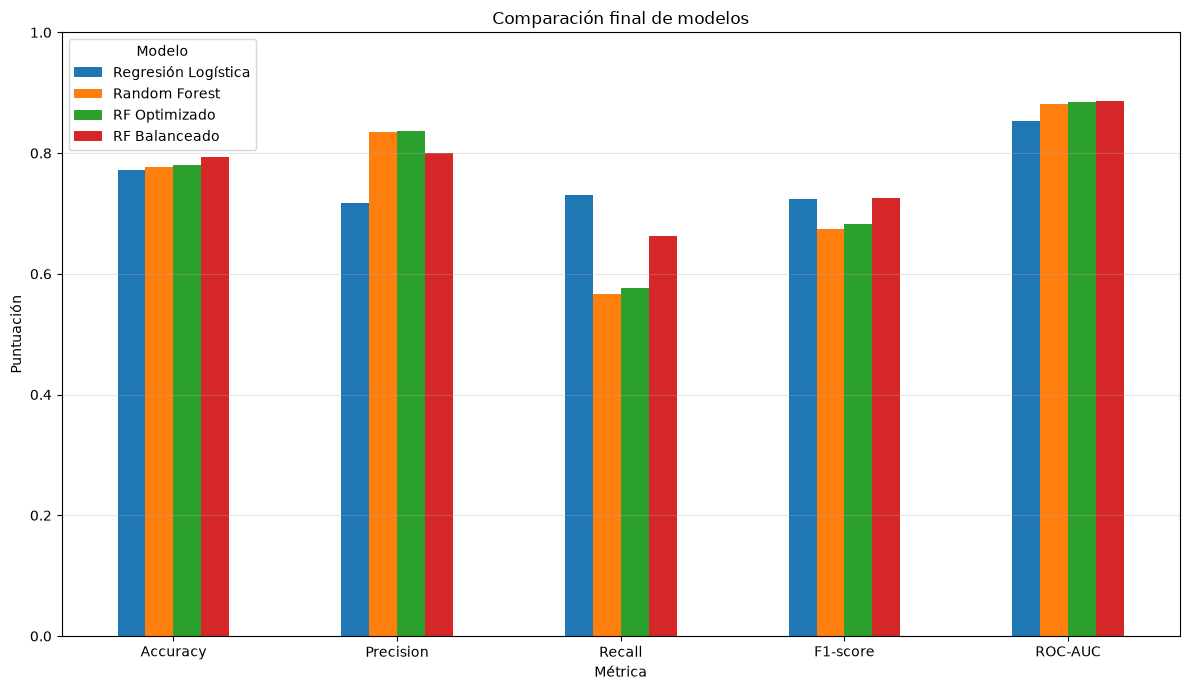

In [52]:
# ============================================================
# COMPARACIÓN FINAL DE MODELOS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Crear tabla comparativa
comparacion_final = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest",
        "RF Optimizado",
        "RF Balanceado"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_opt),
        accuracy_score(y_test, y_pred_rf_bal)
    ],

    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_opt),
        precision_score(y_test, y_pred_rf_bal)
    ],

    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_opt),
        recall_score(y_test, y_pred_rf_bal)
    ],

    "F1-score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_opt),
        f1_score(y_test, y_pred_rf_bal)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_logistic),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_rf_opt),
        roc_auc_score(y_test, y_prob_rf_bal)
    ]
})

print("COMPARACIÓN FINAL DE MODELOS")
print("=" * 80)
print(comparacion_final.round(4).to_string(index=False))


# ============================================================
# GRÁFICO COMPARATIVO
# ============================================================

comparacion_plot = comparacion_final.set_index("Modelo").T

ax = comparacion_plot.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Comparación final de modelos")
plt.ylabel("Puntuación")
plt.xlabel("Métrica")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Modelo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
# Guardar gráfico actualizado
from pathlib import Path

figures_dir = Path("..") / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

ruta_comparacion = figures_dir / "comparacion_final_modelos.png"

plt.savefig(
    ruta_comparacion,
    dpi=300,
    bbox_inches="tight"
)

print(f"\n✅ Figura actualizada guardada en: {ruta_comparacion}")
plt.show()



In [53]:
# ============================================================
# GUARDAR COMPARACIÓN FINAL DE MODELOS
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

comparacion_plot = comparacion_final.set_index("Modelo").T

ax = comparacion_plot.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Comparación final de modelos")
plt.ylabel("Puntuación")
plt.xlabel("Métrica")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Modelo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

ruta = figures_dir / "comparacion_final_modelos.png"
plt.savefig(ruta, dpi=300, bbox_inches="tight")
plt.close()

print(f"Figura guardada correctamente en: {ruta}")

Figura guardada correctamente en: ..\outputs\figures\comparacion_final_modelos.png


### Selección del modelo final

Tras comparar los cuatro enfoques evaluados, se selecciona el **Random Forest Balanceado** como modelo final para una posible aplicación empresarial.

Aunque el Random Forest Optimizado obtiene el ROC-AUC más elevado (**0,8860**), la diferencia respecto al Random Forest Balanceado (**0,8854**) es mínima. En cambio, el modelo balanceado alcanza la mayor **Accuracy (0,7950)** y el mayor **F1-score (0,7268)**, además de incrementar el **Recall hasta 0,6652**, frente al 0,5815 del Random Forest Optimizado.

Esta mejora del Recall resulta especialmente relevante para el problema de negocio, ya que un falso negativo representa una reserva que finalmente se cancela pero que el hotel no había identificado como reserva de riesgo. Este error puede impedir adoptar medidas preventivas y contribuir a que una habitación quede sin ocupar.

Al mismo tiempo, el modelo mantiene una **Precision de 0,8009**, por lo que conserva una capacidad elevada para evitar clasificar indiscriminadamente como peligrosas reservas que finalmente no se cancelarían.

Por tanto, se selecciona el **Random Forest Balanceado** como solución final por ofrecer el equilibrio más adecuado entre discriminación global, detección de cancelaciones y control de falsos positivos para este caso de negocio.

TOP 15 VARIABLES MÁS IMPORTANTES
                        Variable  Importancia
    cat__deposit_type_No Deposit     0.122326
    cat__deposit_type_Non Refund     0.114235
                cat__country_PRT     0.097009
                  num__lead_time     0.082933
     num__previous_cancellations     0.063881
  num__total_of_special_requests     0.063076
                      num__agent     0.049464
                        num__adr     0.031298
num__required_car_parking_spaces     0.026902
      cat__market_segment_Groups     0.021738
   cat__market_segment_Online TA     0.020993
    cat__customer_type_Transient     0.019897
            num__booking_changes     0.018616
   num__arrival_date_week_number     0.017420
       num__stays_in_week_nights     0.017012


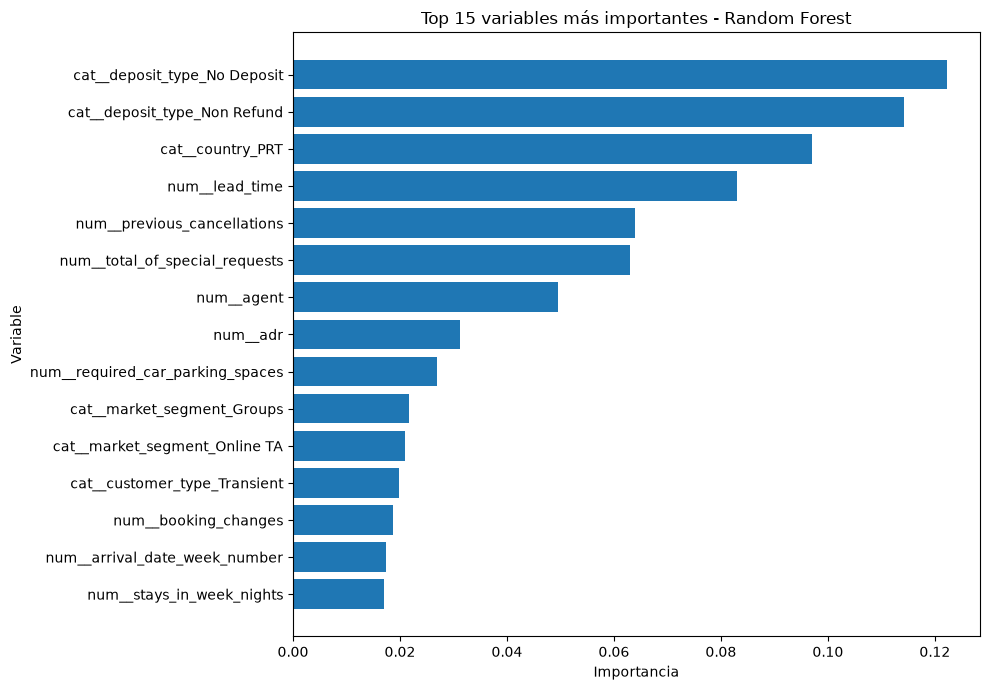

In [54]:
# ============================================================
# IMPORTANCIA DE VARIABLES - RANDOM FOREST
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Obtener nombres de variables después del preprocesamiento
feature_names = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Obtener importancia de cada variable
importances = random_forest_model.named_steps[
    "classifier"
].feature_importances_

# Crear DataFrame
feature_importance = pd.DataFrame({
    "Variable": feature_names,
    "Importancia": importances
})

# Ordenar de mayor a menor
feature_importance = feature_importance.sort_values(
    "Importancia",
    ascending=False
)

# Top 15 variables
top_features = feature_importance.head(15)

print("TOP 15 VARIABLES MÁS IMPORTANTES")
print("=" * 70)
print(top_features.to_string(index=False))

# Gráfico
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Variable"][::-1],
    top_features["Importancia"][::-1]
)

plt.title("Top 15 variables más importantes - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## Interpretabilidad del modelo mediante SHAP

Para interpretar el comportamiento del modelo final se utiliza SHAP (SHapley Additive exPlanations).

El análisis permite identificar qué variables tienen mayor influencia global sobre las predicciones y explicar, a nivel individual, por qué determinadas reservas presentan mayor o menor riesgo de cancelación. Esta interpretabilidad es especialmente relevante desde negocio, ya que permite convertir la predicción del modelo en información útil para Revenue Management.

c:\Users\HP\Desktop\ml-cancelaciones-hoteleras\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


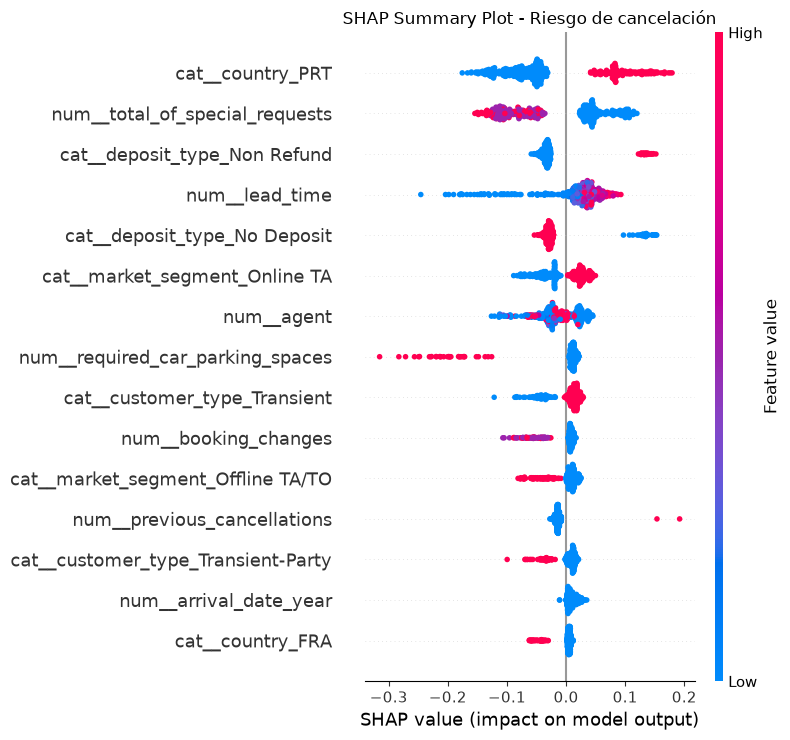

✅ SHAP Summary Plot guardado en: ..\outputs\figures\shap_summary.png


In [55]:
# ============================================================
# SHAP - IMPORTANCIA GLOBAL DE VARIABLES
# Modelo final: Random Forest Balanceado
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Utilizamos el Random Forest balanceado como modelo final
modelo_shap = rf_balanced_model

# Extraemos preprocesador y clasificador
preprocessor_shap = modelo_shap.named_steps["preprocessor"]
classifier_shap = modelo_shap.named_steps["classifier"]

# Transformamos X_test exactamente igual que durante el entrenamiento
X_test_transformed = preprocessor_shap.transform(X_test)

# Nombres de las variables después del preprocesamiento
feature_names_shap = preprocessor_shap.get_feature_names_out()

# Seleccionamos una muestra reproducible para que SHAP sea eficiente
rng = np.random.RandomState(42)
sample_size = min(500, X_test_transformed.shape[0])

sample_positions = rng.choice(
    X_test_transformed.shape[0],
    size=sample_size,
    replace=False
)

X_shap = X_test_transformed[sample_positions]

# Convertimos a formato denso si fuera necesario
if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

X_shap_df = pd.DataFrame(
    X_shap,
    columns=feature_names_shap
)

# Calculamos valores SHAP
explainer = shap.TreeExplainer(classifier_shap)
shap_result = explainer(X_shap_df)

# Random Forest devuelve explicación para las dos clases.
# Nos interesa la clase 1: cancelación.
if shap_result.values.ndim == 3:
    shap_cancel = shap.Explanation(
        values=shap_result.values[:, :, 1],
        base_values=shap_result.base_values[:, 1],
        data=shap_result.data,
        feature_names=feature_names_shap
    )
else:
    shap_cancel = shap_result

# Summary Plot
shap.summary_plot(
    shap_cancel.values,
    X_shap_df,
    feature_names=feature_names_shap,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Riesgo de cancelación")
plt.tight_layout()

# Guardamos la figura
figures_dir = Path("..") / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

ruta_shap = figures_dir / "shap_summary.png"

plt.savefig(
    ruta_shap,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"✅ SHAP Summary Plot guardado en: {ruta_shap}")

RESERVAS SELECCIONADAS PARA INTERPRETACIÓN INDIVIDUAL
🔴 Reserva de riesgo ALTO: 99.93%
🟢 Reserva de riesgo BAJO: 2.16%

🔴 DATOS ORIGINALES - RESERVA DE RIESGO ALTO


,Valor
hotel,City Hotel
lead_time,189
arrival_date_year,2017
arrival_date_month,June
arrival_date_week_number,22
arrival_date_day_of_month,2
stays_in_weekend_nights,0
stays_in_week_nights,2
adults,2
children,0.0



🟢 DATOS ORIGINALES - RESERVA DE RIESGO BAJO


,Valor
hotel,Resort Hotel
lead_time,72
arrival_date_year,2017
arrival_date_month,May
arrival_date_week_number,18
arrival_date_day_of_month,4
stays_in_weekend_nights,2
stays_in_week_nights,5
adults,2
children,0.0


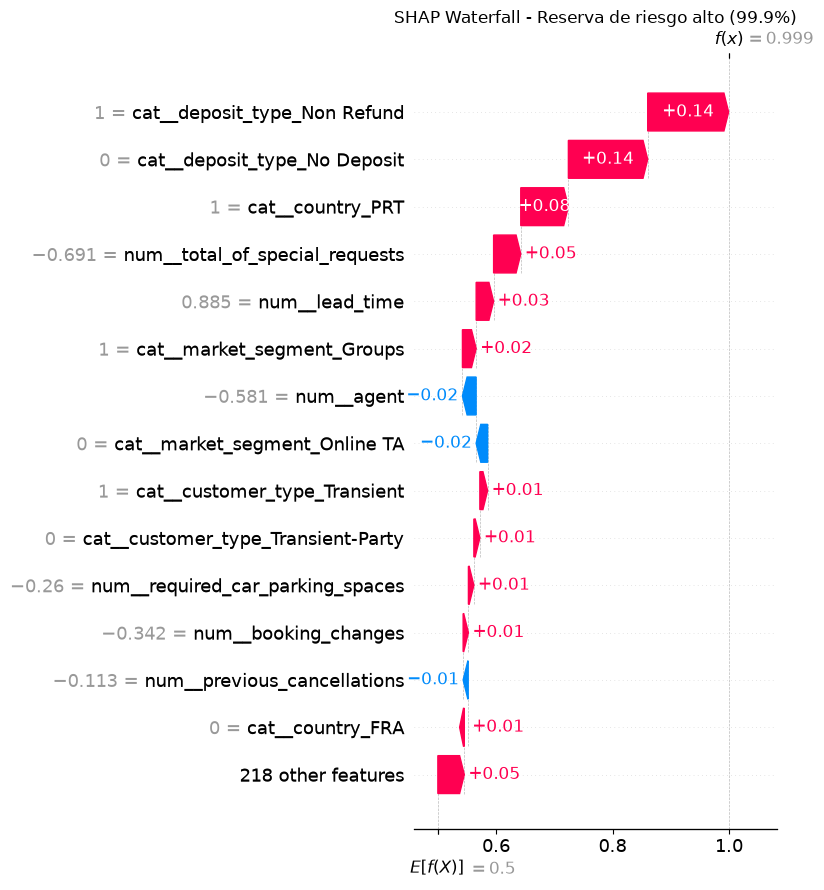

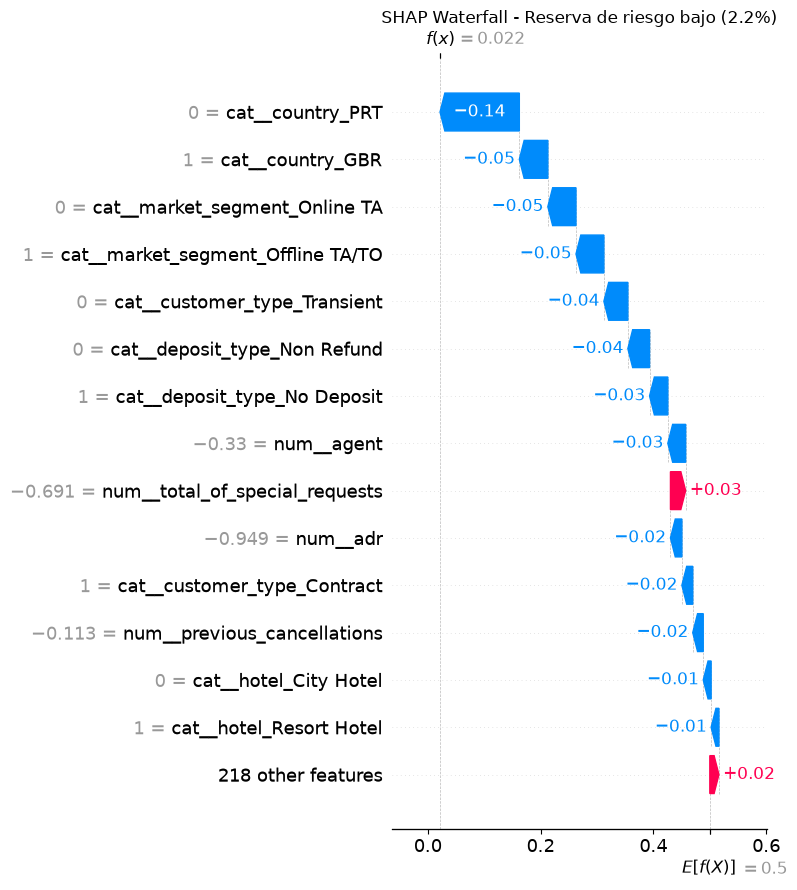


✅ Waterfalls guardados correctamente:
   ..\outputs\figures\shap_waterfall_riesgo_alto.png
   ..\outputs\figures\shap_waterfall_riesgo_bajo.png


In [56]:
# ============================================================
# SHAP WATERFALL - DOS RESERVAS CONCRETAS
# ============================================================

# Probabilidad de cancelación de las reservas utilizadas en SHAP
probabilidades_shap = classifier_shap.predict_proba(X_shap)[:, 1]

# Seleccionamos una reserva de riesgo alto y otra de riesgo bajo
pos_alto = int(np.argmax(probabilidades_shap))
pos_bajo = int(np.argmin(probabilidades_shap))

prob_alto = probabilidades_shap[pos_alto]
prob_bajo = probabilidades_shap[pos_bajo]

print("RESERVAS SELECCIONADAS PARA INTERPRETACIÓN INDIVIDUAL")
print("=" * 65)
print(f"🔴 Reserva de riesgo ALTO: {prob_alto:.2%}")
print(f"🟢 Reserva de riesgo BAJO: {prob_bajo:.2%}")

# Recuperamos las reservas originales para poder interpretarlas
reserva_alto = X_test.iloc[sample_positions[pos_alto]]
reserva_bajo = X_test.iloc[sample_positions[pos_bajo]]

print("\n🔴 DATOS ORIGINALES - RESERVA DE RIESGO ALTO")
display(reserva_alto.to_frame("Valor"))

print("\n🟢 DATOS ORIGINALES - RESERVA DE RIESGO BAJO")
display(reserva_bajo.to_frame("Valor"))

# ------------------------------------------------------------
# WATERFALL - RIESGO ALTO
# ------------------------------------------------------------

shap.plots.waterfall(
    shap_cancel[pos_alto],
    max_display=15,
    show=False
)

plt.title(
    f"SHAP Waterfall - Reserva de riesgo alto ({prob_alto:.1%})"
)
plt.tight_layout()

ruta_waterfall_alto = figures_dir / "shap_waterfall_riesgo_alto.png"

plt.savefig(
    ruta_waterfall_alto,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# WATERFALL - RIESGO BAJO
# ------------------------------------------------------------

shap.plots.waterfall(
    shap_cancel[pos_bajo],
    max_display=15,
    show=False
)

plt.title(
    f"SHAP Waterfall - Reserva de riesgo bajo ({prob_bajo:.1%})"
)
plt.tight_layout()

ruta_waterfall_bajo = figures_dir / "shap_waterfall_riesgo_bajo.png"

plt.savefig(
    ruta_waterfall_bajo,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Waterfalls guardados correctamente:")
print(f"   {ruta_waterfall_alto}")
print(f"   {ruta_waterfall_bajo}")

### Interpretación de negocio mediante SHAP

El análisis SHAP permite identificar tanto los factores que influyen globalmente en el modelo como las razones concretas que explican la predicción de una reserva individual. Esto resulta especialmente útil para Revenue Management, ya que permite conocer no solo qué reservas presentan riesgo de cancelación, sino también qué características están impulsando dicho riesgo.

#### Perfil de una reserva de alto riesgo

La reserva seleccionada como ejemplo de alto riesgo presenta una probabilidad estimada de cancelación del **99,93 %**. Se trata de una reserva de **City Hotel**, realizada con **189 días de antelación**, procedente de **Portugal (PRT)**, perteneciente al segmento **Groups**, gestionada mediante el canal **TA/TO**, de tipo de cliente **Transient** y con depósito **Non Refund**.

El Waterfall Plot muestra que la elevada probabilidad no procede de una única variable, sino de la combinación de diferentes factores. Entre los elementos que más empujan esta predicción hacia la cancelación aparecen determinadas características del **tipo de depósito**, la procedencia **PRT**, un `lead_time` elevado y la pertenencia al segmento **Groups**. La ausencia de peticiones especiales también contribuye al resultado, mientras que otros factores presentan efectos menores o reducen parcialmente el riesgo.

#### Perfil de una reserva de bajo riesgo

Como contraste, la reserva seleccionada de bajo riesgo presenta únicamente un **2,16 %** de probabilidad estimada de cancelación. Corresponde a un **Resort Hotel**, fue realizada con **72 días de antelación**, procede de **Reino Unido (GBR)**, pertenece al segmento **Offline TA/TO**, utiliza el canal **TA/TO**, presenta un depósito de tipo **No Deposit** y corresponde a un cliente de tipo **Contract**.

En este caso, el Waterfall Plot muestra que varias características desplazan la predicción hacia la no cancelación. Entre las contribuciones que reducen el riesgo destacan la combinación concreta de país, segmento de mercado, tipo de cliente, agente y depósito. En conjunto, estos factores hacen que el modelo reduzca considerablemente la probabilidad estimada de cancelación.

#### Conclusión empresarial

Los resultados muestran que **no existe una única característica que determine por sí sola una cancelación**. El riesgo surge de la combinación entre la antelación de la reserva, el tipo de depósito, el segmento y canal de comercialización, el tipo de cliente, el país de procedencia, las peticiones especiales y otras características de la reserva.

La variable creada mediante Feature Engineering, `total_guests`, está disponible para el modelo, aunque no aparece entre los factores de mayor impacto global en el análisis SHAP. Esto indica que, en este conjunto de datos, otras características aportan mayor capacidad explicativa sobre el riesgo de cancelación.

Desde una perspectiva de negocio, el modelo podría utilizarse en el momento de la reserva para generar una **probabilidad individual de cancelación**. Las reservas clasificadas con riesgo elevado podrían ser objeto de medidas preventivas selectivas, como incentivos para mantener la reserva, políticas específicas de depósito, comunicaciones de confirmación o su consideración en las decisiones de overbooking.

La utilización de SHAP permite además justificar estas actuaciones, ya que Revenue Management puede conocer qué factores concretos están provocando una predicción de riesgo elevado. De esta forma se evita aplicar medidas restrictivas de manera indiscriminada a todos los clientes y se facilita una estrategia diferenciada en función del riesgo estimado.


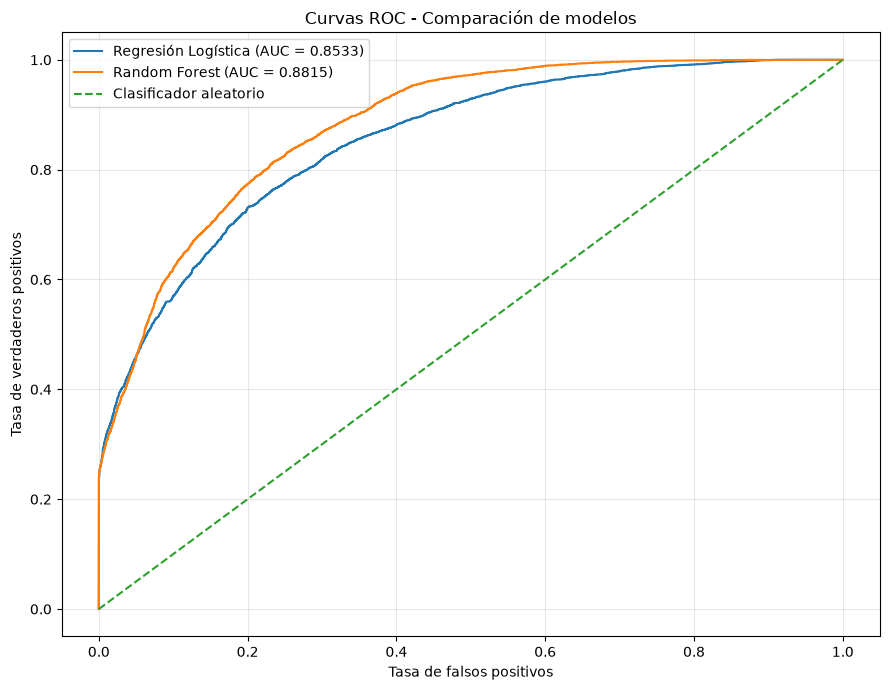

ROC-AUC
Regresión Logística: 0.8533
Random Forest:       0.8815


In [57]:
# ============================================================
# CURVAS ROC - COMPARACIÓN DE MODELOS
# ============================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Curva ROC - Regresión Logística
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

roc_auc_logistic = auc(
    fpr_logistic,
    tpr_logistic
)

# Curva ROC - Random Forest
fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

roc_auc_rf = auc(
    fpr_rf,
    tpr_rf
)

# Gráfico
plt.figure(figsize=(9, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Regresión Logística (AUC = {roc_auc_logistic:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.4f})"
)

# Línea de referencia de clasificación aleatoria
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.title("Curvas ROC - Comparación de modelos")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC")
print("=" * 50)
print(f"Regresión Logística: {roc_auc_logistic:.4f}")
print(f"Random Forest:       {roc_auc_rf:.4f}")

In [58]:
# ============================================================
# GUARDADO DE FIGURAS PRINCIPALES
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Ruta de salida
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

print("GUARDADO DE FIGURAS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Matriz de confusión - Regresión Logística
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["No cancelada", "Cancelada"]
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Regresión Logística")
plt.tight_layout()

ruta = figures_dir / "matriz_confusion_logistica.png"
plt.savefig(ruta, dpi=300, bbox_inches="tight")
plt.close()

print(f"✓ {ruta}")


# ------------------------------------------------------------
# 2. Matriz de confusión - Random Forest
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No cancelada", "Cancelada"]
).plot(ax=ax, cmap="Greens", values_format="d")

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()

ruta = figures_dir / "matriz_confusion_random_forest.png"
plt.savefig(ruta, dpi=300, bbox_inches="tight")
plt.close()

print(f"✓ {ruta}")


# ------------------------------------------------------------
# 4. Curvas ROC
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Regresión Logística (AUC = {roc_auc_logistic:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.title("Curvas ROC - Comparación de modelos")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

ruta = figures_dir / "curvas_roc.png"
plt.savefig(ruta, dpi=300, bbox_inches="tight")
plt.close()

print(f"✓ {ruta}")

print("\nFiguras guardadas correctamente.")

GUARDADO DE FIGURAS
✓ ..\outputs\figures\matriz_confusion_logistica.png
✓ ..\outputs\figures\matriz_confusion_random_forest.png
✓ ..\outputs\figures\curvas_roc.png

Figuras guardadas correctamente.


In [59]:
# ============================================================
# CONCLUSIONES DEL MODELADO - EVALUACIÓN TEMPORAL
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. CÁLCULO DE MÉTRICAS
# ------------------------------------------------------------

# Regresión Logística
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)
roc_auc_logistic = roc_auc_score(y_test, y_prob_logistic)

# Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)


print("CONCLUSIONES DEL MODELADO")
print("=" * 70)

print("\n1. COMPARACIÓN DE MODELOS")
print("-" * 70)

print(
    f"{'Modelo':<22}"
    f"{'Accuracy':>10}"
    f"{'Precision':>12}"
    f"{'Recall':>10}"
    f"{'F1':>10}"
    f"{'ROC-AUC':>12}"
)

print("-" * 74)

print(
    f"{'Regresión Logística':<22}"
    f"{accuracy_logistic:>10.4f}"
    f"{precision_logistic:>12.4f}"
    f"{recall_logistic:>10.4f}"
    f"{f1_logistic:>10.4f}"
    f"{roc_auc_logistic:>12.4f}"
)

print(
    f"{'Random Forest':<22}"
    f"{accuracy_rf:>10.4f}"
    f"{precision_rf:>12.4f}"
    f"{recall_rf:>10.4f}"
    f"{f1_rf:>10.4f}"
    f"{roc_auc_rf:>12.4f}"
)


# ------------------------------------------------------------
# 2. DETECCIÓN DE CANCELACIONES
# ------------------------------------------------------------

print("\n2. DETECCIÓN DE CANCELACIONES")
print("-" * 70)

print(
    f"Regresión Logística detecta correctamente el "
    f"{recall_logistic * 100:.2f}% de las cancelaciones."
)

print(
    f"Random Forest detecta correctamente el "
    f"{recall_rf * 100:.2f}% de las cancelaciones."
)

fn_logistic = ((y_test == 1) & (y_pred_logistic == 0)).sum()
fn_rf = ((y_test == 1) & (y_pred_rf == 0)).sum()

print(
    f"\nCancelaciones no detectadas por Regresión Logística: "
    f"{fn_logistic:,}"
)

print(
    f"Cancelaciones no detectadas por Random Forest: "
    f"{fn_rf:,}"
)


# ------------------------------------------------------------
# 3. INTERPRETACIÓN
# ------------------------------------------------------------

print("\n3. INTERPRETACIÓN")
print("-" * 70)

print(
    "Random Forest obtiene mayor accuracy, precision y ROC-AUC, "
    "por lo que presenta una buena capacidad global de discriminación."
)

print(
    "Sin embargo, la Regresión Logística obtiene un recall superior "
    "para la clase cancelada, detectando una mayor proporción de las "
    "cancelaciones reales."
)

print(
    "Esto es especialmente relevante desde el punto de vista de negocio, "
    "ya que una cancelación no detectada puede dificultar la gestión "
    "de disponibilidad e ingresos del hotel."
)


# ------------------------------------------------------------
# 4. MODELO FINAL
# ------------------------------------------------------------

print("\n4. MODELO FINAL")
print("-" * 70)

print("Modelo utilizado para la clasificación de riesgo: RANDOM FOREST")

print(
    "Se mantiene Random Forest como modelo de scoring debido a su "
    "mayor ROC-AUC y a su capacidad para ordenar las reservas según "
    "su probabilidad estimada de cancelación."
)

print(
    "No obstante, la Regresión Logística obtiene un mayor recall de "
    "cancelaciones, por lo que la elección del modelo dependería del "
    "coste empresarial asociado a falsos positivos y falsos negativos."
)


# ------------------------------------------------------------
# 5. VARIABLES RELEVANTES
# ------------------------------------------------------------

print("\n5. VARIABLES RELEVANTES - RANDOM FOREST")
print("-" * 70)

for i, row in feature_importance.head(5).reset_index(drop=True).iterrows():
    print(
        f"{i + 1}. {row['Variable']} "
        f"(importancia: {row['Importancia']:.4f})"
    )


# ------------------------------------------------------------
# 6. CONCLUSIÓN GENERAL
# ------------------------------------------------------------

print("\n6. CONCLUSIÓN GENERAL")
print("-" * 70)

print(
    "Los resultados muestran que es posible identificar patrones "
    "asociados al riesgo de cancelación utilizando información "
    "disponible sobre las reservas."
)

print(
    "La evaluación temporal proporciona una estimación más realista "
    "del comportamiento de los modelos ante reservas futuras."
)

print(
    "Los dos modelos presentan ventajas diferentes: Random Forest "
    "ofrece mayor capacidad global de discriminación, mientras que "
    "la Regresión Logística detecta una mayor proporción de "
    "cancelaciones."
)

print(
    "Por tanto, la selección definitiva del modelo debería considerar "
    "no solo las métricas predictivas, sino también el coste empresarial "
    "de los distintos tipos de error."
)

CONCLUSIONES DEL MODELADO

1. COMPARACIÓN DE MODELOS
----------------------------------------------------------------------
Modelo                  Accuracy   Precision    Recall        F1     ROC-AUC
--------------------------------------------------------------------------
Regresión Logística       0.7714      0.7168    0.7313    0.7240      0.8533
Random Forest             0.7764      0.8353    0.5663    0.6750      0.8815

2. DETECCIÓN DE CANCELACIONES
----------------------------------------------------------------------
Regresión Logística detecta correctamente el 73.13% de las cancelaciones.
Random Forest detecta correctamente el 56.63% de las cancelaciones.

Cancelaciones no detectadas por Regresión Logística: 2,626
Cancelaciones no detectadas por Random Forest: 4,239

3. INTERPRETACIÓN
----------------------------------------------------------------------
Random Forest obtiene mayor accuracy, precision y ROC-AUC, por lo que presenta una buena capacidad global de discriminación

In [60]:
# ============================================================
# CLASIFICACIÓN DEL RIESGO DE CANCELACIÓN
# ============================================================

import pandas as pd
import numpy as np

# Creamos dataframe con los resultados del conjunto TEST
resultados_test = pd.DataFrame({
    "valor_real": y_test.values,
    "prediccion": y_pred_rf,
    "probabilidad_cancelacion": y_prob_rf
}, index=y_test.index)

# Clasificación del riesgo según probabilidad
resultados_test["nivel_riesgo"] = pd.cut(
    resultados_test["probabilidad_cancelacion"],
    bins=[0, 0.30, 0.60, 1.0],
    labels=["Bajo", "Medio", "Alto"],
    include_lowest=True
)

print("CLASIFICACIÓN DEL RIESGO DE CANCELACIÓN")
print("=" * 70)

print("\nPrimeras reservas analizadas:")
display(resultados_test.head(10))

print("\nDISTRIBUCIÓN POR NIVEL DE RIESGO")
print("-" * 70)

distribucion_riesgo = (
    resultados_test["nivel_riesgo"]
    .value_counts()
    .reindex(["Bajo", "Medio", "Alto"])
)

porcentaje_riesgo = (
    resultados_test["nivel_riesgo"]
    .value_counts(normalize=True)
    .reindex(["Bajo", "Medio", "Alto"])
    * 100
)

resumen_riesgo = pd.DataFrame({
    "Reservas": distribucion_riesgo,
    "Porcentaje": porcentaje_riesgo.round(2)
})

display(resumen_riesgo)

print("\nTASA REAL DE CANCELACIÓN POR NIVEL DE RIESGO")
print("-" * 70)

tasa_real_riesgo = (
    resultados_test
    .groupby("nivel_riesgo", observed=True)["valor_real"]
    .agg(["count", "mean"])
)

tasa_real_riesgo.columns = [
    "Reservas",
    "Tasa_real_cancelacion"
]

tasa_real_riesgo["Tasa_real_cancelacion"] *= 100
tasa_real_riesgo["Tasa_real_cancelacion"] = (
    tasa_real_riesgo["Tasa_real_cancelacion"].round(2)
)

display(tasa_real_riesgo)

CLASIFICACIÓN DEL RIESGO DE CANCELACIÓN

Primeras reservas analizadas:


,valor_real,prediccion,probabilidad_cancelacion,nivel_riesgo
66628,1,1,0.990587,Alto
66603,1,1,0.660271,Alto
66602,1,1,0.990587,Alto
66601,1,1,0.990587,Alto
66600,1,1,0.990587,Alto
66599,1,1,0.990587,Alto
66598,1,1,0.990587,Alto
66597,1,1,0.978192,Alto
66596,1,1,0.990587,Alto
66595,1,1,0.673638,Alto



DISTRIBUCIÓN POR NIVEL DE RIESGO
----------------------------------------------------------------------


,Reservas,Porcentaje
nivel_riesgo,,
Bajo,12006,50.36
Medio,6699,28.10
Alto,5137,21.55



TASA REAL DE CANCELACIÓN POR NIVEL DE RIESGO
----------------------------------------------------------------------


,Reservas,Tasa_real_cancelacion
nivel_riesgo,,
Bajo,12006,13.27
Medio,6699,55.90
Alto,5137,86.33


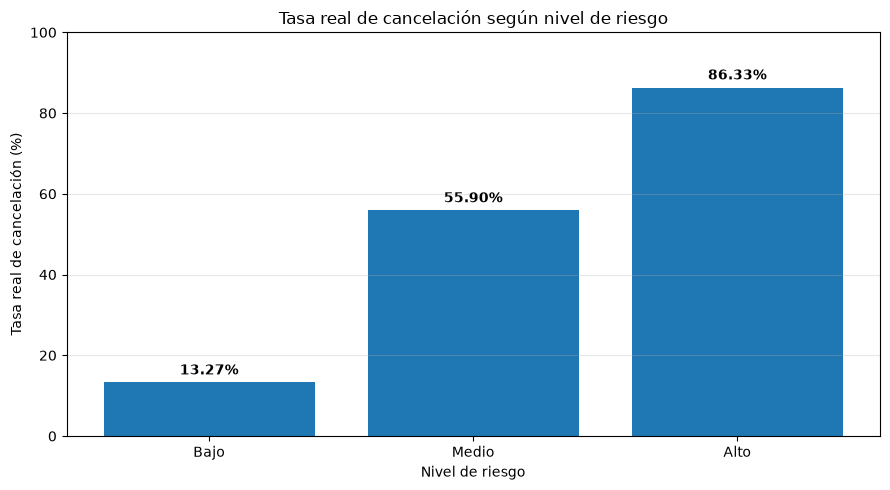

INTERPRETACIÓN
Riesgo Bajo: 12,006 reservas | 13.27% de cancelación real
Riesgo Medio: 6,699 reservas | 55.90% de cancelación real
Riesgo Alto: 5,137 reservas | 86.33% de cancelación real


In [61]:
# ============================================================
# VISUALIZACIÓN DEL RIESGO DE CANCELACIÓN
# ============================================================

import matplotlib.pyplot as plt

orden_riesgo = ["Bajo", "Medio", "Alto"]

datos_grafico = (
    resultados_test
    .groupby("nivel_riesgo", observed=True)["valor_real"]
    .agg(["count", "mean"])
    .reindex(orden_riesgo)
)

datos_grafico["mean"] = datos_grafico["mean"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    datos_grafico.index,
    datos_grafico["mean"]
)

ax.set_title("Tasa real de cancelación según nivel de riesgo")
ax.set_xlabel("Nivel de riesgo")
ax.set_ylabel("Tasa real de cancelación (%)")
ax.set_ylim(0, 100)

# Mostrar porcentaje encima de cada barra
for barra, valor in zip(barras, datos_grafico["mean"]):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 2,
        f"{valor:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("INTERPRETACIÓN")
print("=" * 60)

for nivel in orden_riesgo:
    tasa = datos_grafico.loc[nivel, "mean"]
    cantidad = datos_grafico.loc[nivel, "count"]

    print(
        f"Riesgo {nivel}: {cantidad:,} reservas | "
        f"{tasa:.2f}% de cancelación real"
    )

In [62]:
# ============================================================
# GUARDAR GRÁFICO DE RIESGO
# ============================================================

fig.savefig(
    "../outputs/figures/riesgo_cancelacion.png",
    dpi=300,
    bbox_inches="tight"
)

print("✓ Gráfico guardado correctamente:")
print("../outputs/figures/riesgo_cancelacion.png")

✓ Gráfico guardado correctamente:
../outputs/figures/riesgo_cancelacion.png


# Conclusiones finales

## Resultados del proyecto

El objetivo de este proyecto ha sido desarrollar un modelo de Machine Learning capaz de estimar, en el momento de la reserva, la probabilidad de que una reserva hotelera termine siendo cancelada. Para ello se ha utilizado una división temporal de los datos, de forma que el entrenamiento se realiza con reservas anteriores y la evaluación final con reservas posteriores, reproduciendo de manera más realista un escenario de utilización empresarial.

Se han evaluado cuatro aproximaciones:

- **Regresión Logística**, utilizada como modelo baseline interpretable.
- **Random Forest**.
- **Random Forest optimizado mediante RandomizedSearchCV**.
- **Random Forest Balanceado**, incorporando `class_weight="balanced"` para gestionar el desbalanceo de clases.

Los resultados obtenidos sobre el conjunto de test temporal fueron:

| Modelo | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Regresión Logística | 77,14 % | 71,68 % | 73,13 % | 0,7240 | 0,8533 |
| Random Forest | 77,64 % | 83,53 % | 56,63 % | 0,6750 | 0,8815 |
| RF Optimizado | 78,06 % | 83,70 % | 57,71 % | 0,6832 | 0,8845 |
| RF Balanceado | 79,41 % | 80,07 % | 66,25 % | 0,7251 | 0,8856 |

## Optimización y tratamiento del desbalanceo

La optimización mediante `RandomizedSearchCV` permitió mejorar el Random Forest inicial, obteniendo un ROC-AUC de **0,8845** en el conjunto de test.

También se analizó la distribución de la variable objetivo. En el conjunto de entrenamiento, aproximadamente el **63,9 %** de las reservas corresponden a reservas no canceladas y el **36,1 %** a reservas canceladas.

Para reducir el efecto de este desbalanceo se entrenó un Random Forest utilizando `class_weight="balanced"`.

Esta estrategia incrementó el Recall de la clase cancelada desde el **56,63 %** del Random Forest original hasta el **66,25 %**, al mismo tiempo que alcanzó una Accuracy del **79,41 %**, una Precision del **80,07 %**, un F1-score de **0,7251** y un ROC-AUC de **0,8856**.

## Selección del modelo final

Aunque ningún modelo domina todas las métricas, se selecciona el **Random Forest Balanceado** como modelo final para una posible aplicación empresarial.

La Regresión Logística consigue el mayor Recall (**73,13 %**), pero presenta una Precision y una capacidad discriminativa inferiores. El Random Forest Optimizado mantiene una Precision elevada (**83,70 %**), pero detecta una proporción considerablemente menor de las cancelaciones reales.

El Random Forest Balanceado ofrece un compromiso adecuado para el problema de negocio: mantiene una **Precision del 80,07 %**, aumenta considerablemente el Recall respecto a los otros modelos Random Forest y obtiene el **mayor F1-score (0,7251)** y la **mayor Accuracy (79,41 %)** de las alternativas evaluadas, junto con un ROC-AUC de **0,8856**.

Esta elección resulta relevante porque un falso negativo representa una reserva que finalmente se cancela pero que el hotel no había identificado como de riesgo, pudiendo reducir la capacidad de aplicar medidas preventivas.

## Interpretabilidad y principales factores de riesgo

La utilización de SHAP permite interpretar tanto el comportamiento global del modelo como predicciones individuales.

El análisis global muestra que entre las variables con mayor influencia aparecen el **país de procedencia**, el **número de peticiones especiales**, el **tipo de depósito**, el `lead_time`, el **segmento de mercado**, el agente, el tipo de cliente y otras características relacionadas con las condiciones y el historial de la reserva.

El análisis de reservas individuales permite observar cómo la combinación de estas características modifica el riesgo estimado. Como ejemplo, una de las reservas analizadas alcanza una probabilidad estimada de cancelación del **99,93 %**, mientras que una reserva con características diferentes presenta únicamente un **2,16 %**.

La variable `total_guests`, creada mediante Feature Engineering a partir de adultos, niños y bebés, se encuentra disponible para el modelo. Sin embargo, no aparece entre las variables de mayor impacto global en el análisis SHAP, indicando que otras características presentan una mayor capacidad explicativa del riesgo de cancelación en este conjunto de datos.

## Aplicación empresarial

El modelo podría integrarse en el proceso de gestión de reservas para generar una **probabilidad individual de cancelación en el momento de realizar la reserva**.

A partir de esta probabilidad, Revenue Management podría definir diferentes niveles de riesgo y aplicar medidas de forma selectiva. Entre las posibles actuaciones se encuentran:

- comunicaciones adicionales de confirmación;
- incentivos destinados a mantener reservas de riesgo;
- políticas de depósito adaptadas;
- ofertas o mejoras selectivas;
- utilización de las probabilidades agregadas de cancelación como apoyo a las decisiones de overbooking.

Este enfoque permitiría concentrar las actuaciones en las reservas con mayor riesgo en lugar de aplicar las mismas medidas a todos los clientes. No obstante, cualquier estrategia debería considerar conjuntamente el coste de los falsos negativos y el de los falsos positivos.

## Conclusión

El proyecto demuestra que las técnicas de Machine Learning pueden utilizarse para estimar anticipadamente el riesgo de cancelación de reservas hoteleras utilizando información disponible antes de conocer el resultado final de la reserva.

La utilización de una división temporal, la prevención del Data Leakage, el preprocesamiento mediante pipelines, la optimización de hiperparámetros, el tratamiento del desbalanceo y la interpretación mediante SHAP permiten construir una solución reproducible y orientada al problema empresarial.

Entre las alternativas evaluadas se selecciona el **Random Forest Balanceado** como modelo final debido al equilibrio observado entre Precision, Recall, F1-score, Accuracy y ROC-AUC.

Como siguientes pasos, sería recomendable evaluar el modelo con nuevos periodos temporales, estudiar diferentes umbrales de decisión en función del coste económico de los errores y cuantificar el impacto real de las acciones preventivas antes de su implantación en un entorno hotelero.